### COMPARAISON DES METHODES DE MACHINE LEARNING

## 1. IMPORTS

In [1]:
import os
import sys
import re
import json
import time
import warnings
import logging
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    auc,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    confusion_matrix,
    log_loss,
    brier_score_loss
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False



In [2]:
# ============================================================
# BLOC ANTI-WARNING  (OS + Multi-Processing + Joblib)
# ============================================================

# 1. ENVIRONNEMENT  (OS + C/C++ + OpenMP + BLAS + Joblib)
os.environ["PYTHONWARNINGS"] = "ignore"
os.environ["XGBOOST_VERBOSITY"] = "0"
os.environ["CATBOOST_LOGGING_LEVEL"] = "Silent"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["KMP_WARNINGS"] = "0"
os.environ["OMP_DISPLAY_ENV"] = "FALSE"
os.environ["MKL_VERBOSE"] = "0"
os.environ["OPENBLAS_VERBOSE"] = "0"
os.environ["NUMEXPR_HIDE_WARNINGS"] = "1"
os.environ["JOBLIB_VERBOSITY"] = "0"
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 4)

# 2. DESCRIPTEUR DE FICHIER NOYAU OS (File Descriptor 2 -> devnull)
try:
    _null_fd = os.open(os.devnull, os.O_RDWR)
    os.dup2(_null_fd, 2)  # C/C++ stderr -> devnull
except Exception:
    pass

# 3. INTERCEPTION DU MODULE WARNINGS
warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore")
warnings.showwarning = lambda *args, **kwargs: None

# 4. NUMPY C-EXTENSIONS & MATH ERRORS
np.seterr(all="ignore")

# 5. PANDAS & LOGGING
pd.options.mode.chained_assignment = None
pd.set_option("mode.chained_assignment", None)
logging.disable(logging.CRITICAL)
for name in list(logging.root.manager.loggerDict.keys()):
    logger = logging.getLogger(name)
    logger.setLevel(logging.CRITICAL)
    logger.propagate = False

# 6. NEUTRALISATION DE JOBLIB / MULTIPROCESSING WORKERS (n_jobs=-1)
# Injecte le silence à l'intérieur de CHAQUE processus fils CPU
try:
    import joblib
    from joblib import Parallel
    
    old_parallel = Parallel
    class SilentParallel(old_parallel):
        def __call__(self, *args, **kwargs):
            warnings.filterwarnings("ignore")
            np.seterr(all="ignore")
            return super().__call__(*args, **kwargs)
            
    joblib.Parallel = SilentParallel
    joblib.parallel.Parallel = SilentParallel
except Exception:
    pass

# 7. DÉVIATION DE STDERR PYTHON DANS UN TROU NOIR
class BlackHoleStream:
    def write(self, *args, **kwargs): pass
    def flush(self, *args, **kwargs): pass

sys.stderr = BlackHoleStream()

print("Anti-Warning Activé")

Anti-Warning Activé


## 2. Configuration des chemins et paramètres globaux

In [ ]:
# =========================
# CHEMINS
# =========================

ROOT_DATASETS = Path("DATASETS_cover&interpolation")

DATASET_FOLDERS = [
    "short_step10_nirs20_bio60",
    "medium_step15_nirs30_bio120",
    "long_step30_nirs60_bio180",
]

DATASET_FILES = [
    "ds_nirs.csv",
    "ds_nirs_ecg.csv",
    "ds_nirs_rsp.csv",
    "ds_nirs_ecg_rsp.csv",
]

OUTPUT_DIR = Path("RESULTS_finaux_zscore_calibration")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_OUT = OUTPUT_DIR / "recap_final_zscore_calibration_wpooled.xlsx"


# =========================
# COLONNES
# =========================

COL_GROUPE = "Participant"
COL_LABEL = "KSS_label"

META_COLS = [
    "Participant",
    "KSS",
    "Epoch",
    "Epoch_center_rel_ms",
    "Epoch_center_rel_s",
    "Groupe",
    "KSS_label",
    "has_fNIRS_file",
    "has_ECG_file",
    "has_RSP_file",
    "step_ms",
    "win_fNIRS_ms",
    "win_ECG_ms",
    "win_RSP_ms",
    
    
]

#Exclusion délibérée des scores KSS = 6 afin de maximiser la marge 
# séparatrice entre l'état de vigilance avérée (<= 5) et de somnolence (>= 7).
KSS_ALERTE_MAX = 5
KSS_SOMNOLENT_MIN = 7


# =========================
# CV / NORMALISATION
# =========================

N_FOLDS = 5
SEED = 42


# =========================
# BASELINE Z-SCORE
# =========================

NORM_MODE = "calibration_mean_std"

BASELINE_FALLBACK = "train_mean"  # si baseline manquante pour une feature/participant
CALIBRATION_FILE = "calibration_epochs_all_modalites.csv"
CALIBRATION_FALLBACK = "train_mean"

# "participant", "bloc", "standard", "none","calibration_mean_std"
# participant = z-score par participant
# calibration_mean_std = z-score calculé à partir de mean et std calculés sur la phase de calibration (BL + 5 min de PVT)
# Normalisation Z-Score par Calibration : fNIRS : KSS1-3 normalisés sur la baseline 'pre' ; KSS6 normalisé sur 'post'. Signaux physiologiques (ECG/RSP) : enregistrement continu, normalisation exclusive sur 'pre'.
# bloc = z-score par participant × KSS
# standard = StandardScaler fit train uniquement
# none = pas de normalisation


Z_EPS = 1e-8

# =========================
# PRÉFIXES MODALITÉS
# =========================

PREF = {
    "fNIRS": ("fNIRS_",),
    "ECG": ("ECG_", "HRV_"),
    "RSP": ("RSP_",),
    "RSA": ("RSA_",),
}


In [4]:
# ============================================================
# CONFIG SIMPLE : 
# ============================================================

# Dossiers de fenêtres à lancer
RUN_DATASET_FOLDERS = [
        "short_step10_nirs20_bio60",
    "medium_step15_nirs30_bio120",
    "long_step30_nirs60_bio180",
]

# Datasets à lancer
RUN_DATASET_FILES = [
    "ds_nirs.csv",
    "ds_nirs_ecg.csv",
    "ds_nirs_rsp.csv",
    "ds_nirs_ecg_rsp.csv",
]

# Modes de réduction à lancer
# Important :
# - toute décorrélation est uniquement fNIRS
# - jamais de décorrélation ECG/RSP/RSA
RUN_REDUCTION_MODES = [
    "full_decorr_fnirs",
    #"fnirs_topk_corr_k30",
    "fnirs_topk_corr_k40",
    # "fnirs_topk_corr_k60",
    "fnirs_topk_corr_k80",
    "fnirs_topk_corr_k120",
    "fnirs_global_chrom",
    "fnirs_hemi_chrom",
    "fnirs_global_chrom_decorr",
    "fnirs_hemi_chrom_decorr",
]

# Modèles à lancer
RUN_MODEL_NAMES = [
    "LogReg_ElasticNet",
    "Linear_SVM",
    "RBF_SVM",
    "RandomForest",
    "ExtraTrees",
    "HistGradientBoosting",
    "XGBoost",
    "CatBoost",
]

# Paramètres preprocessing
MAX_NAN_RATE_FEATURE = 0.40       # appliqué à toutes les features
CORR_FNIRS = 0.9                # décorrélation uniquement fNIRS
TOPK_SCORE_METHOD = "mutual_info" # "mutual_info" ou "f_classif"
K_FNIRS_PREFILTER = 200           # préfiltre avant top-k décorrélé

SKIP_DUPLICATE_NO_FNIRS_REDUCTIONS = True

# =========================
# IMPORTANCE DES FEATURES MODÈLE
# =========================
# Extraction à chaque fold.
# - Si le modèle a une importance native : feature_importances_ / coef_ / CatBoost.
# - Sinon : permutation_importance sur le fold test.

TOP_MODEL_FEATURES = 30

USE_PERMUTATION_IMPORTANCE = True
PERMUTATION_N_REPEATS = 5
PERMUTATION_SCORING = "average_precision"
PERMUTATION_N_JOBS = -1


## 3. Mapping hémisphères

In [5]:
HEMISPHERE_MAP = {
    "Rx1Tx1": "G",
    "Rx1Tx3": "G",
    "Rx2Tx1": "G",
    "Rx2Tx3": "G",

    "Rx3Tx4": "D",
    "Rx3Tx5": "D",
    "Rx4Tx4": "D",
    "Rx4Tx5": "D",
}

AUTO_HEMI_BY_SORTED_SPLIT = False


## 4. Outils colonnes/modalités

In [6]:
# =========================
# PRÉFIXES FEATURES ROBUSTES
# =========================

FEATURE_PREFIXES = ("fnirs", "ecg", "hrv", "rsp", "rsa")

PREF = {
    "fNIRS": ("fnirs",),
    "ECG": ("ecg", "hrv"),
    "RSP": ("rsp",),
    "RSA": ("rsa",),
}

def _col_lower(c):
    return str(c).strip().lower()

def is_feature_col(c):
    return _col_lower(c).startswith(FEATURE_PREFIXES)

def select_feature_cols(cols):
    return [c for c in cols if is_feature_col(c)]

def get_cols_by_prefix(X_or_cols, prefixes):
    cols = X_or_cols.columns if isinstance(X_or_cols, pd.DataFrame) else X_or_cols
    prefixes = tuple(str(p).lower() for p in prefixes)
    return [c for c in cols if _col_lower(c).startswith(prefixes)]

def get_modality_cols(X_or_cols, modality):
    return get_cols_by_prefix(X_or_cols, PREF[modality])

def infer_modalities_from_columns(cols):
    mods = []
    for mod in ["fNIRS", "ECG", "RSP", "RSA"]:
        if len(get_modality_cols(cols, mod)) > 0:
            mods.append(mod)
    return mods

def has_fnirs(cols):
    return len(get_modality_cols(cols, "fNIRS")) > 0

def infer_feature_modality(feature):
    f = _col_lower(feature)
    if f.startswith("fnirs"):
        return "fNIRS"
    if f.startswith(("ecg", "hrv")):
        return "ECG"
    if f.startswith("rsp"):
        return "RSP"
    if f.startswith("rsa"):
        return "RSA"
    return "OTHER"


## 5. Parser fNIRS et agrégations globales

In [7]:
HB_ALIASES = {
    # Oxy-hémoglobine
    "O2Hb": "O2Hb",
    "HbO": "O2Hb",
    "HbO2": "O2Hb",
    "oxyHb": "O2Hb",
    "OxyHb": "O2Hb",

    # Désoxy-hémoglobine
    "HHb": "HHb",
    "HbR": "HHb",
    "HBR": "HHb",
    "deoxyHb": "HHb",
    "DeoxyHb": "HHb",

    # Hémoglobine totale
    "tHb": "tHb",
    "THb": "tHb",
    "HbT": "tHb",
    "hbt": "tHb",
    "HbTot": "tHb",
    "TotalHb": "tHb",

    # Différence HbO - HbR
    "HbDiff": "HbDiff",
    "Hbdiff": "HbDiff",
    "HbDIFF": "HbDiff",
    "Hb_Diff": "HbDiff",
    "hbdiff": "HbDiff",
}

HB_TOKENS = list(HB_ALIASES.keys())


def parse_fnirs_col(col):
    """
    Parse une colonne fNIRS.

    Exemples :
        fNIRS_Rx1Tx1_O2Hb_0_Mean
        fNIRS_Rx1Tx1_HHb_0_Mean
        fNIRS_Rx1Tx1_tHb_0_Mean
        fNIRS_Rx1Tx1_HbDiff_0_Mean
    """
    if not str(col).startswith("fNIRS_"):
        return None
    
    parts = str(col).split("_")
    if len(parts) < 3:
        return None
    
    hb_idx = None
    hb_raw = None
    
    for i, p in enumerate(parts):
        if p in HB_TOKENS:
            hb_idx = i
            hb_raw = p
            break
    
    if hb_idx is None:
        return None
    
    chrom = HB_ALIASES.get(hb_raw, hb_raw)
    channel_parts = parts[1:hb_idx]
    channel = "_".join(channel_parts)
    
    feat_parts = parts[hb_idx + 1:]
    
    # Supprime l'indice numérique type "_0_"
    if len(feat_parts) > 0 and str(feat_parts[0]).isdigit():
        feat_parts = feat_parts[1:]
    
    feature = "_".join(feat_parts) if len(feat_parts) else "value"
    
    if channel == "":
        channel = "unknown_channel"
    
    return {
        "channel": channel,
        "chrom": chrom,
        "feature": feature,
    }



def discover_fnirs_channels(cols):
    channels = sorted({
        parse_fnirs_col(c)["channel"]
        for c in cols
        if parse_fnirs_col(c) is not None
    })
    return channels


def build_auto_hemi_map(cols):
    """
    Inférence naïve : première moitié des canaux triés = G, deuxième = D.
    À utiliser seulement pour debug, pas pour résultats scientifiques.
    """
    channels = discover_fnirs_channels(cols)
    n = len(channels)
    auto_map = {}
    for i, ch in enumerate(channels):
        auto_map[ch] = "G" if i < n / 2 else "D"
    return auto_map


def fit_fnirs_aggregation_mapping(cols, mode):
    """
    Construit le mapping :
        nouvelle_feature -> liste anciennes_features
    pour les réductions fNIRS.
    """
    fnirs_cols = get_modality_cols(cols, "fNIRS")
    
    if len(fnirs_cols) == 0:
        return {}
    
    if mode not in ["fnirs_global_chrom", "fnirs_hemi_chrom"]:
        return {}
    
    parsed = {}
    for c in fnirs_cols:
        info = parse_fnirs_col(c)
        if info is not None:
            parsed[c] = info
    
    if len(parsed) == 0:
        print("[WARNING] Aucune colonne fNIRS parsable. Pas d'agrégation.")
        return {}
    
    hemi_map = dict(HEMISPHERE_MAP)
    
    if mode == "fnirs_hemi_chrom":
        if AUTO_HEMI_BY_SORTED_SPLIT and len(hemi_map) == 0:
            hemi_map = build_auto_hemi_map(fnirs_cols)
            print("[WARNING] Hémisphères inférés automatiquement. À éviter pour résultats finaux.")
            print(hemi_map)
        
        missing_channels = sorted({
            info["channel"]
            for info in parsed.values()
            if info["channel"] not in hemi_map
        })
        
        if len(missing_channels) > 0:
            raise ValueError(
                "HEMISPHERE_MAP incomplet pour fnirs_hemi_chrom. "
                f"Canaux manquants : {missing_channels}. "
                "Vérifier que tous les canaux sont renseignés dans HEMISPHERE_MAP."
            )
    
    groups = defaultdict(list)
    
    for c, info in parsed.items():
        chrom = info["chrom"]
        feat = info["feature"]
        channel = info["channel"]
        
        if mode == "fnirs_global_chrom":
            new_name = f"fNIRS_GLOBAL_{chrom}_{feat}"
        
        elif mode == "fnirs_hemi_chrom":
            hemi = hemi_map[channel]
            new_name = f"fNIRS_HEMI_{hemi}_{chrom}_{feat}"
        
        groups[new_name].append(c)
    
    return dict(groups)


def apply_fnirs_aggregation(X, mapping):
    """
    Remplace les colonnes fNIRS originales par les colonnes agrégées.
    Les colonnes ECG/RSP/RSA sont conservées.
    """
    if len(mapping) == 0:
        return X.copy()
    
    fnirs_cols = set(get_modality_cols(X, "fNIRS"))
    non_fnirs_cols = [c for c in X.columns if c not in fnirs_cols]
    
    X_out = X[non_fnirs_cols].copy()
    
    for new_col, old_cols in mapping.items():
        existing = [c for c in old_cols if c in X.columns]
        if len(existing) == 0:
            X_out[new_col] = np.nan
        else:
            X_out[new_col] = X[existing].mean(axis=1, skipna=True)
    
    return X_out


## 6. Filtres preprocessing features datasets

In [8]:
def drop_bad_nan_features(Xtr, Xte, max_nan_rate=0.40, verbose=False):
    """
    Supprime les features qui ont trop de NaN dans le train fold.

    Important :
        - Le calcul se fait uniquement sur Xtr.
        - La même suppression est appliquée à Xte.
        - Le seuil s'applique à toutes les modalités :
          fNIRS, ECG/HRV, RSP, RSA.
    """
    nan_rate = Xtr.isna().mean()

    cols_drop = nan_rate[nan_rate > max_nan_rate].index.tolist()

    if verbose:
        print(f"[NaN filter] Drop {len(cols_drop)} features avec NaN rate > {max_nan_rate:.0%}")
        if cols_drop:
            print(cols_drop[:50])

    return (
        Xtr.drop(columns=cols_drop, errors="ignore"),
        Xte.drop(columns=cols_drop, errors="ignore"),
        cols_drop
    )



def drop_constant_features(Xtr, Xte, verbose=False):
    nunique = Xtr.nunique(dropna=True)
    cols_drop = nunique[nunique <= 1].index.tolist()
    
    if verbose:
        print(f"[Unique filter] Drop {len(cols_drop)} features constantes/quasi vides")
        if cols_drop:
            print(cols_drop[:30])
    
    return (
        Xtr.drop(columns=cols_drop, errors="ignore"),
        Xte.drop(columns=cols_drop, errors="ignore"),
        cols_drop
    )


def impute_median(Xtr, Xte):
    imputer = SimpleImputer(strategy="median")
    
    Xtr_imp = pd.DataFrame(
        imputer.fit_transform(Xtr),
        columns=Xtr.columns,
        index=Xtr.index
    )
    
    Xte_imp = pd.DataFrame(
        imputer.transform(Xte),
        columns=Xte.columns,
        index=Xte.index
    )
    
    # Sécurité rare : si une colonne est encore NaN.
    Xtr_imp = Xtr_imp.fillna(0)
    Xte_imp = Xte_imp.fillna(0)
    
    return Xtr_imp, Xte_imp, imputer


def zscore_par_groupe(Xdf, meta, mode="participant", eps=1e-8):
    """
    Z-score par groupe.

    Cas spécial mode="participant" :
        - Les features fNIRS de KSS6 sont normalisées UNIQUEMENT sur le bloc KSS6
          (enregistrement fNIRS distinct des KSS 1,2,3).
        - Les features fNIRS des autres KSS sont normalisées ensemble par participant.
        - Les features BIO (ECG/HRV/RSP/RSA) restent normalisées par participant
          sur toutes les époques (même enregistrement).
    """
    if mode == "bloc":
        cle = ["Participant", "KSS"]
        cles = [meta[c].values for c in cle]
        mu = Xdf.groupby(cles).transform("mean")
        sd = Xdf.groupby(cles).transform("std").replace(0, eps).fillna(eps)
        return (Xdf - mu) / sd

    if mode != "participant":
        raise ValueError("mode doit être 'participant' ou 'bloc'")

    # ---- Mode participant avec isolation fNIRS KSS6 ----
    participant = meta["Participant"].values
    kss6_mask = is_kss6(meta)  # bool array aligné sur les lignes de Xdf

    fnirs_cols = set(get_modality_cols(Xdf, "fNIRS"))

    # Clé de groupe fNIRS : (Participant, is_kss6)
    # -> sépare KSS6 des autres KSS pour un même participant
    key_fnirs = pd.Series(
        [f"{p}__{int(k6)}" for p, k6 in zip(participant, kss6_mask)],
        index=Xdf.index
    )

    # Clé de groupe BIO : Participant uniquement (enregistrement unique)
    key_bio = pd.Series(participant, index=Xdf.index)

    Xout = Xdf.copy()

    for c in Xdf.columns:
        if c in fnirs_cols:
            grp = key_fnirs
        else:
            grp = key_bio

        mu = Xdf[c].groupby(grp).transform("mean")
        sd = Xdf[c].groupby(grp).transform("std").replace(0, eps).fillna(eps)
        Xout[c] = (Xdf[c] - mu) / sd

    return Xout



def normalize_train_test(
    Xtr,
    Xte,
    meta_tr,
    meta_te,
    norm_mode="participant",
    baseline_means=None,
    calibration_stats=None,
):
    if norm_mode in ["participant", "bloc"]:
        Xtr_z = zscore_par_groupe(Xtr, meta_tr, mode=norm_mode, eps=Z_EPS)
        Xte_z = zscore_par_groupe(Xte, meta_te, mode=norm_mode, eps=Z_EPS)
        return Xtr_z, Xte_z, None

    elif norm_mode == "standard":
        scaler = StandardScaler()
        Xtr_z = pd.DataFrame(
            scaler.fit_transform(Xtr),
            columns=Xtr.columns,
            index=Xtr.index
        )
        Xte_z = pd.DataFrame(
            scaler.transform(Xte),
            columns=Xte.columns,
            index=Xte.index
        )
        return Xtr_z, Xte_z, scaler

    elif norm_mode == "baseline_mean_train_std":
        Xtr_z, Xte_z, scaler_like = zscore_baseline_mean_train_std(
            Xtr=Xtr,
            Xte=Xte,
            meta_tr=meta_tr,
            meta_te=meta_te,
            baseline_means=baseline_means,
            eps=Z_EPS,
            fallback=BASELINE_FALLBACK
        )
        return Xtr_z, Xte_z, scaler_like

    elif norm_mode == "calibration_mean_std":
        Xtr_z, Xte_z, scaler_like = zscore_calibration_mean_std(
            Xtr=Xtr,
            Xte=Xte,
            meta_tr=meta_tr,
            meta_te=meta_te,
            calibration_stats=calibration_stats,
            eps=Z_EPS,
            fallback=CALIBRATION_FALLBACK
        )
        return Xtr_z, Xte_z, scaler_like

    elif norm_mode == "none":
        return Xtr.copy(), Xte.copy(), None

    else:
        raise ValueError(
            "NORM_MODE doit être 'participant', 'bloc', 'standard', "
            "'baseline_mean_train_std', 'calibration_mean_std' ou 'none'"

        )



def correlation_filter_train_only(Xtr, Xte, threshold=0.95, verbose=False):
    if Xtr.shape[1] <= 1:
        return Xtr, Xte, []
    
    corr = Xtr.corr(numeric_only=True).abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    
    cols_drop = [
        col for col in upper.columns
        if (upper[col] >= threshold).any()
    ]
    
    if verbose:
        print(f"[Correlation filter] Drop {len(cols_drop)} features corrélées >= {threshold}")
        if cols_drop:
            print(cols_drop[:30])
    
    return (
        Xtr.drop(columns=cols_drop, errors="ignore"),
        Xte.drop(columns=cols_drop, errors="ignore"),
        cols_drop
    )


In [9]:
def clean_feature_columns(df):
    bad = [
        c for c in df.columns
        if str(c).startswith("Unnamed")
        or str(c).lower() in ["index", "level_0"]
    ]
    if bad:
        df = df.drop(columns=bad, errors="ignore")
    return df, bad


## CALIBRATION

In [10]:
def load_calibration_epochs_csv(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Fichier calibration absent : {path}")

    dfc = pd.read_csv(path)
    dfc = dfc.replace([np.inf, -np.inf], np.nan)
    dfc, bad_cols = clean_feature_columns(dfc)

    if "Participant" not in dfc.columns:
        raise ValueError("Colonne Participant absente du fichier calibration.")

    if "Calibration_bloc" not in dfc.columns:
        raise ValueError("Colonne Calibration_bloc absente du fichier calibration.")

    dfc["Participant"] = pd.to_numeric(dfc["Participant"], errors="coerce").astype("Int64")
    dfc["Calibration_bloc"] = dfc["Calibration_bloc"].astype(str)

    # IMPORTANT :
    # fNIRS : pre + post
    # BIO : uniquement pre, BIO post ignoré
    if "Calibration_modality" in dfc.columns:
        modality = dfc["Calibration_modality"].astype(str)

        keep_fnirs = modality.eq("fNIRS")
        keep_bio_pre = modality.eq("BIO") & dfc["Calibration_bloc"].eq("pre")

        dfc = dfc[keep_fnirs | keep_bio_pre].copy()

    return dfc


In [11]:
def compute_calibration_stats_for_current_space(
    calibration_epochs_raw,
    raw_feature_cols,
    aggregation_mapping=None ):
    
    if calibration_epochs_raw is None:
        return None

    feature_cols = [c for c in raw_feature_cols if c in calibration_epochs_raw.columns]

    if len(feature_cols) == 0:
        print("[WARNING] Aucune feature commune entre dataset courant et calibration.")
        return None

    C_meta = calibration_epochs_raw[["Participant", "Calibration_bloc"]].copy()
    C_feat = calibration_epochs_raw[feature_cols].copy()

    for c in C_feat.columns:
        C_feat[c] = pd.to_numeric(C_feat[c], errors="coerce")

    # Même agrégation fNIRS que dans le fold courant
    if aggregation_mapping is not None and len(aggregation_mapping) > 0:
        C_feat = apply_fnirs_aggregation(C_feat, aggregation_mapping)

    C = pd.concat([C_meta.reset_index(drop=True), C_feat.reset_index(drop=True)],axis=1)

    mu = (C.groupby(["Participant", "Calibration_bloc"]).mean(numeric_only=True))

    sd = (C.groupby(["Participant", "Calibration_bloc"]).std(numeric_only=True, ddof=0))

    return {"mu": mu,"sd": sd,}


In [12]:
def is_kss6(meta):
    s = meta["KSS"].astype(str).str.upper()
    s = s.str.replace("KSS", "", regex=False)
    s = pd.to_numeric(s, errors="coerce")
    return s.eq(6).values


In [13]:
def zscore_calibration_mean_std(
    Xtr,
    Xte,
    meta_tr,
    meta_te,
    calibration_stats,
    eps=1e-8,
    fallback="train_mean"
):
    """
    Règle :
    - fNIRS :
        KSS6 -> calibration post
        autres KSS -> calibration pre
    - ECG / HRV / RSP / RSA :
        toujours calibration pre
    """
    if calibration_stats is None:
        raise ValueError("calibration_stats est None alors que NORM_MODE='calibration_mean_std'.")

    calib_mu = calibration_stats["mu"].copy()
    calib_sd = calibration_stats["sd"].copy()

    cols = Xtr.columns.tolist()

    for c in cols:
        if c not in calib_mu.columns:
            calib_mu[c] = np.nan
        if c not in calib_sd.columns:
            calib_sd[c] = np.nan

    calib_mu = calib_mu[cols]
    calib_sd = calib_sd[cols]

    train_mean = Xtr.mean(axis=0)
    train_std = Xtr.std(axis=0, ddof=0).replace(0, eps).fillna(eps)

    fnirs_cols = set(get_modality_cols(cols, "fNIRS"))

    def build_mu_sd(meta, index):
        participants = pd.to_numeric(meta["Participant"], errors="coerce").astype("Int64")
        kss6_mask = is_kss6(meta)

        mu = pd.DataFrame(index=index, columns=cols, dtype=float)
        sd = pd.DataFrame(index=index, columns=cols, dtype=float)

        for c in cols:

            if c in fnirs_cols:
                # fNIRS : KSS6 post, sinon pre
                blocs = np.where(kss6_mask, "post", "pre")
            else:
                # BIO : toujours pre, même pour KSS6
                blocs = np.array(["pre"] * len(meta))

            keys = pd.MultiIndex.from_arrays(
                [participants.values, blocs],
                names=["Participant", "Calibration_bloc"]
            )

            mu_c = calib_mu[c].reindex(keys).to_numpy()
            sd_c = calib_sd[c].reindex(keys).to_numpy()

            # Si fNIRS post manquant, fallback vers pre du même participant
            if c in fnirs_cols:
                miss = pd.isna(mu_c)
                if miss.any():
                    keys_pre = pd.MultiIndex.from_arrays(
                        [
                            participants.values[miss],
                            np.array(["pre"] * miss.sum())
                        ],
                        names=["Participant", "Calibration_bloc"]
                    )
                    mu_c[miss] = calib_mu[c].reindex(keys_pre).to_numpy()
                    sd_c[miss] = calib_sd[c].reindex(keys_pre).to_numpy()

            mu[c] = mu_c
            sd[c] = sd_c

        if fallback == "train_mean":
            mu = mu.fillna(train_mean)
            sd = sd.replace(0, eps).fillna(train_std)
        elif fallback == "zero":
            mu = mu.fillna(0)
            sd = sd.replace(0, eps).fillna(eps)
        else:
            raise ValueError("fallback doit être 'train_mean' ou 'zero'.")

        sd = sd.replace(0, eps).fillna(eps)

        return mu, sd

    mu_tr, sd_tr = build_mu_sd(meta_tr, Xtr.index)
    mu_te, sd_te = build_mu_sd(meta_te, Xte.index)

    Xtr_z = (Xtr - mu_tr) / sd_tr
    Xte_z = (Xte - mu_te) / sd_te

    return Xtr_z, Xte_z, {
        "calibration_mu": calib_mu,
        "calibration_sd": calib_sd,
        "fallback": fallback,
    }


## 7. Décorrélation fNIRS + top-k fNIRS

In [14]:
from sklearn.feature_selection import mutual_info_classif, f_classif
import numpy as np
import pandas as pd


def safe_scores(X_mod, y, score_method="mutual_info", random_state=42):
    """
    Score supervisé feature par feature, uniquement sur le train.
    """
    if X_mod.shape[1] == 0:
        return np.array([])
    
    if score_method == "mutual_info":
        scores = mutual_info_classif(
            X_mod,
            y,
            random_state=random_state,
            discrete_features=False
        )
    elif score_method == "f_classif":
        scores, _ = f_classif(X_mod, y)
    else:
        raise ValueError("score_method doit être 'mutual_info' ou 'f_classif'")
    
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    return scores


def compute_feature_scores(Xtr, ytr, score_method="mutual_info", random_state=42):
    """
    Retourne une Series :
        index = noms features
        values = scores supervisés
    """
    scores = safe_scores(
        Xtr,
        ytr,
        score_method=score_method,
        random_state=random_state
    )
    
    return pd.Series(scores, index=Xtr.columns, name="score")


def correlation_prune_by_score(
    Xtr,
    feature_scores,
    candidate_cols,
    corr_threshold=0.95,
    max_features=None,
    verbose=False
):
    """
    Décorrélation greedy guidée par score supervisé.

    Principe :
        1. trie les candidates par score décroissant ;
        2. garde la meilleure ;
        3. supprime les features trop corrélées aux features déjà gardées ;
        4. continue jusqu'à épuisement ou max_features.

    Important :
        - Xtr uniquement
        - Xtr déjà imputé et normalisé
    """
    candidate_cols = [c for c in candidate_cols if c in Xtr.columns]
    
    if len(candidate_cols) == 0:
        return [], []
    
    ordered_cols = (
        feature_scores
        .reindex(candidate_cols)
        .fillna(0.0)
        .sort_values(ascending=False)
        .index
        .tolist()
    )
    
    corr = Xtr[ordered_cols].corr().abs()
    
    kept = []
    dropped_corr = []
    
    for c in ordered_cols:
        if len(kept) == 0:
            kept.append(c)
        else:
            max_corr = corr.loc[c, kept].max()
            
            if max_corr >= corr_threshold:
                dropped_corr.append(c)
            else:
                kept.append(c)
        
        if max_features is not None and len(kept) >= max_features:
            break
    
    if verbose:
        print(
            f"[Corr prune by score] candidates={len(candidate_cols)} | "
            f"kept={len(kept)} | dropped_corr={len(dropped_corr)} | "
            f"threshold={corr_threshold}"
        )
    
    return kept, dropped_corr


def decorrelate_fnirs_keep_non_fnirs(
    Xtr,
    ytr,
    Xte,
    corr_threshold=0.95,
    score_method="mutual_info",
    random_state=42,
    verbose=False
):
    """
    Mode :
        full_decorr_fnirs
        fnirs_global_chrom_decorr
        fnirs_hemi_chrom_decorr

    Garde :
        - toutes les features non-fNIRS restantes après filtres qualité ;
        - les fNIRS décorrélées.

    Ne décorrèle jamais ECG/HRV, RSP, RSA.
    """
    fnirs_cols = get_modality_cols(Xtr, "fNIRS")
    non_fnirs_cols = [c for c in Xtr.columns if c not in fnirs_cols]
    
    if len(fnirs_cols) == 0:
        empty_score_df = pd.DataFrame(columns=[
            "feature", "score", "modality", "selected_final"
        ])
        return Xtr.copy(), Xte.copy(), Xtr.columns.tolist(), empty_score_df, []
    
    scores_fnirs = compute_feature_scores(
        Xtr[fnirs_cols],
        ytr,
        score_method=score_method,
        random_state=random_state
    )
    
    kept_fnirs, dropped_corr = correlation_prune_by_score(
        Xtr=Xtr,
        feature_scores=scores_fnirs,
        candidate_cols=fnirs_cols,
        corr_threshold=corr_threshold,
        max_features=None,
        verbose=verbose
    )
    
    final_cols = kept_fnirs + non_fnirs_cols
    final_cols = list(dict.fromkeys(final_cols))
    
    score_df = (
        scores_fnirs
        .reset_index()
        .rename(columns={"index": "feature", "score": "score"})
        .sort_values("score", ascending=False)
    )
    score_df["modality"] = "fNIRS"
    score_df["selected_final"] = score_df["feature"].isin(kept_fnirs)
    
    if verbose:
        print("\n[decorrelate_fnirs_keep_non_fnirs]")
        print(f"fNIRS initiales       : {len(fnirs_cols)}")
        print(f"fNIRS gardées         : {len(kept_fnirs)}")
        print(f"fNIRS drop corr       : {len(dropped_corr)}")
        print(f"Non-fNIRS conservées  : {len(non_fnirs_cols)}")
        print(f"Total final           : {len(final_cols)}")
    
    return Xtr[final_cols], Xte[final_cols], final_cols, score_df, dropped_corr


def select_fnirs_topk_decorrelated_keep_non_fnirs(
    Xtr,
    ytr,
    Xte,
    k_final=40,
    k_prefilter=250,
    corr_threshold=0.95,
    score_method="mutual_info",
    random_state=42,
    verbose=False
):
    """
    Mode :
        fnirs_topk_corr_kXX

    Garde :
        - toutes les features non-fNIRS restantes après filtres qualité ;
        - top k_final fNIRS décorrélées.

    Ne décorrèle jamais ECG/HRV, RSP, RSA.
    """
    fnirs_cols = get_modality_cols(Xtr, "fNIRS")
    non_fnirs_cols = [c for c in Xtr.columns if c not in fnirs_cols]
    
    if len(fnirs_cols) == 0:
        empty_score_df = pd.DataFrame(columns=[
            "feature", "score", "modality", "selected_final"
        ])
        return Xtr.copy(), Xte.copy(), Xtr.columns.tolist(), empty_score_df, []
    
    scores_fnirs = compute_feature_scores(
        Xtr[fnirs_cols],
        ytr,
        score_method=score_method,
        random_state=random_state
    )
    
    score_df = (
        scores_fnirs
        .reset_index()
        .rename(columns={"index": "feature", "score": "score"})
        .sort_values("score", ascending=False)
    )
    score_df["modality"] = "fNIRS"
    
    # Préfiltre par score, borné correctement
    k_prefilter_eff = min(max(k_final, k_prefilter), len(score_df))
    pre_cols = score_df.head(k_prefilter_eff)["feature"].tolist()
    
    kept_fnirs, dropped_corr = correlation_prune_by_score(
        Xtr=Xtr,
        feature_scores=scores_fnirs,
        candidate_cols=pre_cols,
        corr_threshold=corr_threshold,
        max_features=k_final,
        verbose=verbose
    )
    
    final_cols = kept_fnirs + non_fnirs_cols
    final_cols = list(dict.fromkeys(final_cols))
    
    score_df["selected_final"] = score_df["feature"].isin(kept_fnirs)
    
    if verbose:
        print(f"\n[fnirs_topk_corr_k{k_final}]")
        print(f"fNIRS initiales       : {len(fnirs_cols)}")
        print(f"Préfiltre score       : {len(pre_cols)}")
        print(f"fNIRS finales         : {len(kept_fnirs)}")
        print(f"fNIRS drop corr       : {len(dropped_corr)}")
        print(f"Non-fNIRS conservées  : {len(non_fnirs_cols)}")
        print(f"Total final           : {len(final_cols)}")
    
    return Xtr[final_cols], Xte[final_cols], final_cols, score_df, dropped_corr


## 8. Modèles

In [15]:
def get_models(seed=42):
    models = {}
    
    models["LogReg_ElasticNet"] = LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=0.5,
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=seed,
        n_jobs=-1
    )
    
    models["Linear_SVM"] = LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=20000,
        random_state=seed
    )
    
    models["RBF_SVM"] = SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=False,
        random_state=seed
    )
    
    models["RandomForest"] = RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed
    )
    
    models["ExtraTrees"] = ExtraTreesClassifier(
        n_estimators=500,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed
    )
    
    models["HistGradientBoosting"] = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        l2_regularization=0.1,
        random_state=seed
    )
    
    if HAS_XGB :
        models["XGBoost"] = XGBClassifier(
            n_estimators=400,
            learning_rate=0.03,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=3,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            n_jobs=-1,
            random_state=seed
        )

    if HAS_CAT : 
        models["CatBoost"] = CatBoostClassifier(
            iterations=500,
            learning_rate=0.03,
            depth=4,
            loss_function="Logloss",
            eval_metric="AUC",
            auto_class_weights="Balanced",
            random_seed=seed,
            verbose=False
        )
    
    return models


MODELS_ALL = get_models(SEED)

# Garde uniquement les modèles demandés et disponibles
MODELS_RUN = {}

for name in RUN_MODEL_NAMES:
    if name in MODELS_ALL:
        MODELS_RUN[name] = MODELS_ALL[name]
    else:
        print(f"[WARNING] Modèle demandé mais indisponible ou mal nommé : {name}")

print("Modèles lancés :")
for name in MODELS_RUN:
    print("-", name)


Modèles lancés :
- LogReg_ElasticNet
- Linear_SVM
- RBF_SVM
- RandomForest
- ExtraTrees
- HistGradientBoosting
- XGBoost
- CatBoost


## 9. Métriques

In [16]:
def get_scores_and_pred(model, Xte):
    """
    Retourne :
        score continu pour AUC
        proba si disponible
        prédiction avec seuil par défaut
    """
    proba = None
    
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]
        score = proba
        pred = (proba >= 0.5).astype(int)
    
    elif hasattr(model, "decision_function"):
        score = model.decision_function(Xte)
        pred = (score >= 0).astype(int)
    
    else:
        pred = model.predict(Xte)
        score = pred.astype(float)
    
    return score, proba, pred


def compute_metrics(y_true, score, pred, proba=None):
    y_true = np.asarray(y_true)
    pred = np.asarray(pred)
    
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    
    out = {}
    
    if len(np.unique(y_true)) == 2:
        out["roc_auc"] = roc_auc_score(y_true, score)
        out["average_precision"] = average_precision_score(y_true, score)
        
        # PR-AUC par intégration trapézoïdale
        precision_pts, recall_pts, _ = precision_recall_curve(y_true, score)
        out["pr_auc"] = auc(recall_pts, precision_pts)
    else:
        out["roc_auc"] = np.nan
        out["average_precision"] = np.nan
        out["pr_auc"] = np.nan
    
    out.update({
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "f1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall_sensitivity": recall_score(y_true, pred, zero_division=0),
        "specificity": specificity,
        "mcc": matthews_corrcoef(y_true, pred) if len(np.unique(pred)) > 1 else 0.0,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    })
    
    if proba is not None:
        try:
            out["log_loss"] = log_loss(y_true, proba, labels=[0, 1])
        except Exception:
            out["log_loss"] = np.nan
        try:
            out["brier_score"] = brier_score_loss(y_true, proba)
        except Exception:
            out["brier_score"] = np.nan
    else:
        out["log_loss"] = np.nan
        out["brier_score"] = np.nan
    
    return out


In [17]:
def infer_feature_modality(feature):
    """
    Déduit la modalité à partir du nom de feature.
    Compatible avec les préfixes standards du projet (fNIRS, ECG, HRV, RSP, RSA).
    """
    feature = str(feature)
    
    if feature.startswith("fNIRS_"):
        return "fNIRS"
    
    if feature.startswith("ECG_") or feature.startswith("HRV_"):
        return "ECG"
    
    if feature.startswith("RSP_"):
        return "RSP"
    
    if feature.startswith("RSA_"):
        return "RSA"
    
    return "OTHER"


def _safe_permutation_scoring(y_ref, requested_scoring):
    """
    Évite les erreurs de permutation_importance avec roc_auc
    si un fold test ne contient qu'une seule classe.
    """
    y_ref = np.asarray(y_ref)
    
    if requested_scoring == "roc_auc" and len(np.unique(y_ref)) < 2:
        return "balanced_accuracy"
    
    return requested_scoring


def extract_model_feature_importance(
    fitted_model,
    X_ref,
    y_ref=None,
    top_n=30,
    use_permutation=True,
    permutation_scoring="roc_auc",
    permutation_n_repeats=3,
    permutation_n_jobs=-1,
    random_state=42
):
    """
    Extrait les features importantes pour tous les modèles possibles.

    Priorité :
        1. feature_importances_ :
           RandomForest, ExtraTrees, XGBoost sklearn API, certains boosters.
        2. coef_ :
           LogisticRegression, LinearSVC, modèles linéaires.
        3. get_feature_importance :
           CatBoost si nécessaire.
        4. permutation_importance :
           fallback pour RBF_SVM, HistGradientBoosting, etc.

    Pour permutation_importance :
        - Calcul effectué sur les sous-ensembles de test pour évaluer la généralisation.
        - les importances peuvent être négatives ;
        - le ranking utilise surtout la partie positive.
    """
    if X_ref is None or X_ref.shape[1] == 0:
        return pd.DataFrame()
    
    features = np.array(X_ref.columns)
    
    importance = None
    importance_std = None
    importance_type = None
    signed_coef = None
    
    # ======================================================
    # 1. Modèles avec feature_importances_
    # ======================================================
    if hasattr(fitted_model, "feature_importances_"):
        try:
            importance = np.asarray(fitted_model.feature_importances_, dtype=float)
            importance_std = np.full(len(features), np.nan)
            importance_type = "feature_importances"
        except Exception:
            importance = None
            importance_std = None
            importance_type = None
    
    # ======================================================
    # 2. Modèles linéaires avec coef_
    # ======================================================
    if importance is None and hasattr(fitted_model, "coef_"):
        try:
            coef = np.asarray(fitted_model.coef_, dtype=float)
            
            if coef.ndim == 1:
                signed_coef = coef
                importance = np.abs(coef)
            
            elif coef.shape[0] == 1:
                signed_coef = coef[0]
                importance = np.abs(coef[0])
            
            else:
                # Cas multiclasse éventuel : moyenne des |coef| par feature.
                signed_coef = np.full(coef.shape[1], np.nan)
                importance = np.mean(np.abs(coef), axis=0)
            
            importance_std = np.full(len(features), np.nan)
            importance_type = "abs_coef"
        
        except Exception:
            importance = None
            importance_std = None
            importance_type = None
            signed_coef = None
    
    # ======================================================
    # 3. CatBoost get_feature_importance si besoin
    # ======================================================
    if importance is None and hasattr(fitted_model, "get_feature_importance"):
        try:
            importance = np.asarray(fitted_model.get_feature_importance(), dtype=float)
            importance_std = np.full(len(features), np.nan)
            importance_type = "catboost_feature_importance"
        except Exception:
            importance = None
            importance_std = None
            importance_type = None
    
    # ======================================================
    # 4. Fallback permutation_importance
    # ======================================================
    if importance is None and use_permutation and y_ref is not None:
        try:
            from sklearn.inspection import permutation_importance
            
            scoring_eff = _safe_permutation_scoring(
                y_ref=y_ref,
                requested_scoring=permutation_scoring
            )
            
            perm = permutation_importance(
                fitted_model,
                X_ref,
                y_ref,
                scoring=scoring_eff,
                n_repeats=permutation_n_repeats,
                random_state=random_state,
                n_jobs=permutation_n_jobs
            )
            
            importance = np.asarray(perm.importances_mean, dtype=float)
            importance_std = np.asarray(perm.importances_std, dtype=float)
            importance_type = f"permutation_importance_{scoring_eff}"
        
        except Exception as e:
            print(f"[WARNING] permutation_importance impossible : {repr(e)}")
            return pd.DataFrame()
    
    if importance is None:
        return pd.DataFrame()
    
    if len(importance) != len(features):
        print(
            "[WARNING] Taille importance incompatible : "
            f"n_importances={len(importance)} | n_features={len(features)}"
        )
        return pd.DataFrame()
    
    if importance_std is None or len(importance_std) != len(features):
        importance_std = np.full(len(features), np.nan)
    
    df_imp = pd.DataFrame({
        "feature": features,
        "importance": importance,
        "importance_std": importance_std,
        "importance_type": importance_type,
    })
    
    if signed_coef is not None and len(signed_coef) == len(features):
        df_imp["signed_coef"] = signed_coef
    else:
        df_imp["signed_coef"] = np.nan
    
    df_imp["importance_abs"] = np.abs(df_imp["importance"])
    df_imp["importance_pos"] = np.maximum(df_imp["importance"], 0)
    
    # Importance utilisée pour classer.
    # Pour les coefficients, importance = |coef|.
    # Pour les arbres, importance >= 0.
    # Pour permutation, on évite de valoriser une grosse importance négative.
    if str(importance_type).startswith("permutation_importance"):
        df_imp["ranking_importance"] = df_imp["importance_pos"]
    else:
        df_imp["ranking_importance"] = df_imp["importance_abs"]
    
    # Normalisations utiles.
    total_abs = np.nansum(df_imp["importance_abs"].values)
    total_rank = np.nansum(df_imp["ranking_importance"].values)
    
    if total_abs > 0:
        df_imp["importance_norm"] = df_imp["importance"] / total_abs
        df_imp["importance_abs_norm"] = df_imp["importance_abs"] / total_abs
    else:
        df_imp["importance_norm"] = np.nan
        df_imp["importance_abs_norm"] = np.nan
    
    if total_rank > 0:
        df_imp["ranking_importance_norm"] = df_imp["ranking_importance"] / total_rank
    else:
        df_imp["ranking_importance_norm"] = np.nan
    
    df_imp["modality"] = df_imp["feature"].apply(infer_feature_modality)
    
    df_imp = (
        df_imp
        .sort_values(
            ["ranking_importance", "importance"],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )
    
    df_imp["rank"] = np.arange(1, len(df_imp) + 1)
    
    if top_n is not None:
        df_imp = df_imp.head(top_n).copy()
    
    return df_imp


## 10. Chargement dataset et rapport

In [18]:
def load_and_prepare_dataset(csv_path):
    df = pd.read_csv(csv_path)
    df = df.replace([np.inf, -np.inf], np.nan)
    
    df, bad_cols = clean_feature_columns(df)
    
    if COL_LABEL not in df.columns:
        raise ValueError(f"{COL_LABEL} absent de {csv_path}")
    
    if COL_GROUPE not in df.columns:
        raise ValueError(f"{COL_GROUPE} absent de {csv_path}")
    
    # Binarisation KSS : classe 6 supprimée.
    kss = df[COL_LABEL]
    df = df[(kss <= KSS_ALERTE_MAX) | (kss >= KSS_SOMNOLENT_MIN)].copy()
    df["y"] = (df[COL_LABEL] >= KSS_SOMNOLENT_MIN).astype(int)
    
    feature_cols = select_feature_cols(df.columns)
    
    # Garde uniquement numérique côté features.
    # Si une colonne feature non numérique existe, on tente conversion.
    for c in feature_cols:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    
    X = df[feature_cols].reset_index(drop=True)
    y = df["y"].reset_index(drop=True)
    
    meta_cols_available = [c for c in ["Participant", "KSS"] if c in df.columns]
    meta = df[meta_cols_available].reset_index(drop=True)
    
    groups = df[COL_GROUPE].reset_index(drop=True)
    
    return df.reset_index(drop=True), X, y, meta, groups, bad_cols


def dataset_report(csv_path, df, X, y, groups, bad_cols):
    mods = infer_modalities_from_columns(X.columns)
    
    rep = {
        "csv_path": str(csv_path),
        "dataset_folder": Path(csv_path).parent.name,
        "dataset_file": Path(csv_path).name,
        "n_rows": len(X),
        "n_features": X.shape[1],
        "n_participants": groups.nunique(),
        "class_0": int((y == 0).sum()),
        "class_1": int((y == 1).sum()),
        "class_1_rate": float((y == 1).mean()) if len(y) else np.nan,
        "nan_total": int(X.isna().sum().sum()),
        "nan_rate_global": float(X.isna().sum().sum() / X.size) if X.size else np.nan,
        "modalities": ",".join(mods),
        "n_fnirs_features": len(get_modality_cols(X, "fNIRS")),
        "n_ecg_features": len(get_modality_cols(X, "ECG")),
        "n_rsp_features": len(get_modality_cols(X, "RSP")),
        "n_rsa_features": len(get_modality_cols(X, "RSA")),
        "dropped_bad_index_cols": ",".join(bad_cols),
    }
    
    if "KSS" in df.columns:
        counts_kss = df["KSS"].value_counts(dropna=False).to_dict()
        rep["kss_counts_json"] = json.dumps({str(k): int(v) for k, v in counts_kss.items()})
    
    return rep


def top_nan_features_report(X, csv_path, top=30):
    nan_count = X.isna().sum().sort_values(ascending=False)
    nan_rate = X.isna().mean().sort_values(ascending=False)
    
    out = pd.DataFrame({
        "dataset_folder": Path(csv_path).parent.name,
        "dataset_file": Path(csv_path).name,
        "feature": nan_count.index,
        "nan_count": nan_count.values,
        "nan_rate": nan_rate.loc[nan_count.index].values,
    })
    
    out = out[out["nan_count"] > 0].head(top)
    return out


## 11. Fit d'un modèle sur un fold

In [19]:
def fit_model_with_optional_sample_weight(model, Xtr, ytr):
    """
    Gestion robuste du déséquilibre.
    Certains modèles ont class_weight.
    Pour HGB/XGB, on utilise sample_weight ou scale_pos_weight.
    """
    model = clone(model)
    
    sample_weight = compute_sample_weight(class_weight="balanced", y=ytr)
    
    # XGBoost : on ajuste scale_pos_weight dans le clone si possible.
    if HAS_XGB and isinstance(model, XGBClassifier):
        n0 = int((np.asarray(ytr) == 0).sum())
        n1 = int((np.asarray(ytr) == 1).sum())
        spw = n0 / max(n1, 1)
        model.set_params(scale_pos_weight=spw)
        model.fit(Xtr, ytr)
        return model
    
    # CatBoost a auto_class_weights="Balanced", pas besoin sample_weight.
    if HAS_CAT and isinstance(model, CatBoostClassifier):
        model.fit(Xtr, ytr)
        return model
    
    # HistGradientBoosting accepte sample_weight.
    if isinstance(model, HistGradientBoostingClassifier):
        model.fit(Xtr, ytr, sample_weight=sample_weight)
        return model
    
    # Autres modèles : class_weight déjà défini quand dispo.
    model.fit(Xtr, ytr)
    return model


## 12. Cross-validation complète pour un dataset × réduction × modèle

In [20]:
import re

def parse_topk_from_reduction_mode(reduction_mode):
    """
    Extrait k depuis un nom du type :
        fnirs_topk_corr_k30
        fnirs_topk_corr_k40
        fnirs_topk_corr_k60
        fnirs_topk_corr_k80
    """
    m = re.search(r"_k(\d+)$", str(reduction_mode))
    if m is None:
        return None
    return int(m.group(1))


In [21]:
def run_cv_one_setting(
    X,
    y,
    meta,
    groups,
    dataset_folder,
    dataset_file,
    reduction_mode,
    model_name,
    model,
    calibration_epochs_raw=None,
    n_splits=5,
    verbose=False
):
    oof_y_true = []
    oof_scores = []
    
    gkf = GroupKFold(n_splits=n_splits)
    # GroupKFold par 'Participant' : garantit l'étanchéité inter-sujets (aucun participant présent simultanément dans le train et le test fold).
    
    fold_rows = []
    selected_feature_rows = []
    dropped_feature_rows = []
    model_feature_rows = []
    
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups), start=1):
        t0 = time.time()
        
        Xtr_raw = X.iloc[tr].copy()
        Xte_raw = X.iloc[te].copy()
        ytr = y.iloc[tr].copy()
        yte = y.iloc[te].copy()
        groups_tr = groups.iloc[tr].copy()
        groups_te = groups.iloc[te].copy()
        meta_tr = meta.iloc[tr].copy()
        meta_te = meta.iloc[te].copy()
        
        n_features_initial = Xtr_raw.shape[1]
        nan_train_initial = int(Xtr_raw.isna().sum().sum())
        nan_test_initial = int(Xte_raw.isna().sum().sum())
        
        # ==========================================================
        # 1) Réduction fNIRS non supervisée : global chrom / hemi
        # ==========================================================
        aggregation_mapping = {}
        
        if reduction_mode in ["fnirs_global_chrom", "fnirs_global_chrom_decorr"]:
            aggregation_mapping = fit_fnirs_aggregation_mapping(
                Xtr_raw.columns,
                mode="fnirs_global_chrom"
            )
            Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
            Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)
        
        elif reduction_mode in ["fnirs_hemi_chrom", "fnirs_hemi_chrom_decorr"]:
            aggregation_mapping = fit_fnirs_aggregation_mapping(
                Xtr_raw.columns,
                mode="fnirs_hemi_chrom"
            )
            Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
            Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)
        
        else:
            Xtr = Xtr_raw.copy()
            Xte = Xte_raw.copy()
        
        n_features_after_aggregation = Xtr.shape[1]
        
        # ==========================================================
        # Baseline dans le même espace de features que le fold courant
        # ==========================================================
        baseline_means_current = None
        
        if NORM_MODE == "baseline_mean_train_std":
            baseline_means_current = compute_baseline_means_for_current_space(
                baseline_epochs_raw=BASELINE_EPOCHS_RAW,
                raw_feature_cols=Xtr_raw.columns,
                aggregation_mapping=aggregation_mapping
            )
        calibration_stats_current = None

        if NORM_MODE == "calibration_mean_std":
            calibration_stats_current = compute_calibration_stats_for_current_space(
                calibration_epochs_raw=calibration_epochs_raw,
                raw_feature_cols=Xtr_raw.columns,
                aggregation_mapping=aggregation_mapping
            )
        
        # ==========================================================
        # 2) Drop features trop NaN sur train
        # ==========================================================
        Xtr, Xte, dropped_nan = drop_bad_nan_features(
            Xtr,
            Xte,
            max_nan_rate=MAX_NAN_RATE_FEATURE,
            verbose=False
        )
        
        # ==========================================================
        # 3) Drop features constantes sur train
        # ==========================================================
        Xtr, Xte, dropped_const = drop_constant_features(
            Xtr,
            Xte,
            verbose=False
        )
        
        # ==========================================================
        # 4) Imputation médiane fit train
        # ==========================================================
        Xtr, Xte, imputer = impute_median(Xtr, Xte)
        
        # ==========================================================
        # 5) Normalisation
        # ==========================================================
        Xtr, Xte, scaler = normalize_train_test(
            Xtr,
            Xte,
            meta_tr,
            meta_te,
            norm_mode=NORM_MODE,
            baseline_means=baseline_means_current,
            calibration_stats=calibration_stats_current
        )
        
        # ==========================================================
        # 6) Décorrélation / sélection fNIRS uniquement
        # ==========================================================
        selected_cols = Xtr.columns.tolist()
        score_df_fnirs = pd.DataFrame()
        dropped_corr_fnirs = []
        k_fnirs_topk = np.nan
        
        if reduction_mode == "full_decorr_fnirs":
            (
                Xtr,
                Xte,
                selected_cols,
                score_df_fnirs,
                dropped_corr_fnirs
            ) = decorrelate_fnirs_keep_non_fnirs(
                Xtr=Xtr,
                ytr=ytr,
                Xte=Xte,
                corr_threshold=CORR_FNIRS,
                score_method=TOPK_SCORE_METHOD,
                random_state=SEED,
                verbose=False
            )
        
        elif reduction_mode.startswith("fnirs_topk_corr_k"):
            k_fnirs_topk = parse_topk_from_reduction_mode(reduction_mode)
            
            if k_fnirs_topk is None:
                raise ValueError(f"Impossible de parser k dans reduction_mode={reduction_mode}")
            
            (
                Xtr,
                Xte,
                selected_cols,
                score_df_fnirs,
                dropped_corr_fnirs
            ) = select_fnirs_topk_decorrelated_keep_non_fnirs(
                Xtr=Xtr,
                ytr=ytr,
                Xte=Xte,
                k_final=k_fnirs_topk,
                k_prefilter=K_FNIRS_PREFILTER,
                corr_threshold=CORR_FNIRS,
                score_method=TOPK_SCORE_METHOD,
                random_state=SEED,
                verbose=False
            )
        
        elif reduction_mode in ["fnirs_global_chrom", "fnirs_hemi_chrom"]:
            pass
        
        elif reduction_mode in ["fnirs_global_chrom_decorr", "fnirs_hemi_chrom_decorr"]:
            (
                Xtr,
                Xte,
                selected_cols,
                score_df_fnirs,
                dropped_corr_fnirs
            ) = decorrelate_fnirs_keep_non_fnirs(
                Xtr=Xtr,
                ytr=ytr,
                Xte=Xte,
                corr_threshold=CORR_FNIRS,
                score_method=TOPK_SCORE_METHOD,
                random_state=SEED,
                verbose=False
            )
        
        else:
            raise ValueError(f"reduction_mode inconnu : {reduction_mode}")
        
        # Log scores/sélections fNIRS
        if len(score_df_fnirs) > 0:
            for rank, row_score in enumerate(score_df_fnirs.head(250).itertuples(index=False), start=1):
                selected_feature_rows.append({
                    "dataset_folder": dataset_folder,
                    "dataset_file": dataset_file,
                    "reduction_mode": reduction_mode,
                    "model": model_name,
                    "fold": fold,
                    "modality": "fNIRS",
                    "feature": row_score.feature,
                    "score": row_score.score,
                    "rank": rank,
                    "selected_final": bool(row_score.selected_final),
                })
        
        n_features_final = Xtr.shape[1]
        
        # ==========================================================
        # 7) Fit modèle + métriques + importance features modèle
        # ==========================================================
        try:
            fitted = fit_model_with_optional_sample_weight(model, Xtr, ytr)
            score, proba, pred = get_scores_and_pred(fitted, Xte)
            oof_y_true.extend(yte.values)
            oof_scores.extend(score)
            metrics = compute_metrics(yte, score, pred, proba=proba)
            
            # ------------------------------------------------------
            # Importance des features du modèle entraîné sur ce fold
            # ------------------------------------------------------
            # On passe Xte/yte :
            # - pour les importances natives, seules les colonnes servent ;
            # - pour permutation_importance, le calcul se fait sur test fold.
            imp_df = extract_model_feature_importance(
                fitted_model=fitted,
                X_ref=Xte,
                y_ref=yte,
                top_n=TOP_MODEL_FEATURES,
                use_permutation=USE_PERMUTATION_IMPORTANCE,
                permutation_scoring=PERMUTATION_SCORING,
                permutation_n_repeats=PERMUTATION_N_REPEATS,
                permutation_n_jobs=PERMUTATION_N_JOBS,
                random_state=SEED
            )
            
            if len(imp_df) > 0:
                for row_imp in imp_df.itertuples(index=False):
                    model_feature_rows.append({
                        "dataset_folder": dataset_folder,
                        "dataset_file": dataset_file,
                        "reduction_mode": reduction_mode,
                        "model": model_name,
                        "fold": fold,
                        "feature": row_imp.feature,
                        "modality": row_imp.modality,
                        "importance": row_imp.importance,
                        "importance_abs": row_imp.importance_abs,
                        "importance_pos": row_imp.importance_pos,
                        "importance_norm": row_imp.importance_norm,
                        "importance_abs_norm": row_imp.importance_abs_norm,
                        "ranking_importance": row_imp.ranking_importance,
                        "ranking_importance_norm": row_imp.ranking_importance_norm,
                        "importance_std": row_imp.importance_std,
                        "rank": row_imp.rank,
                        "importance_type": row_imp.importance_type,
                        "signed_coef": row_imp.signed_coef,
                    })
            
            status = "ok"
            error_msg = ""
        
        except Exception as e:
            metrics = {
                "roc_auc": np.nan,
                "average_precision": np.nan,
                "accuracy": np.nan,
                "balanced_accuracy": np.nan,
                "f1": np.nan,
                "precision": np.nan,
                "recall_sensitivity": np.nan,
                "specificity": np.nan,
                "mcc": np.nan,
                "log_loss": np.nan,
                "brier_score": np.nan,
                "tn": np.nan,
                "fp": np.nan,
                "fn": np.nan,
                "tp": np.nan,
            }
            status = "error"
            error_msg = repr(e)
        
        elapsed = time.time() - t0
        
        row = {
            "dataset_folder": dataset_folder,
            "dataset_file": dataset_file,
            "reduction_mode": reduction_mode,
            "model": model_name,
            "fold": fold,
            "status": status,
            "error": error_msg,
            "k_fnirs_topk": k_fnirs_topk,
            "n_train": len(tr),
            "n_test": len(te),
            "n_train_participants": groups_tr.nunique(),
            "n_test_participants": groups_te.nunique(),
            "train_class_0": int((ytr == 0).sum()),
            "train_class_1": int((ytr == 1).sum()),
            "test_class_0": int((yte == 0).sum()),
            "test_class_1": int((yte == 1).sum()),
            "n_features_initial": n_features_initial,
            "n_features_after_aggregation": n_features_after_aggregation,
            "n_features_final": n_features_final,
            "nan_train_initial": nan_train_initial,
            "nan_test_initial": nan_test_initial,
            "n_dropped_nan": len(dropped_nan),
            "n_dropped_const": len(dropped_const),
            "n_dropped_corr_fnirs": len(dropped_corr_fnirs),
            "elapsed_sec": elapsed,
        }
        row.update(metrics)
        fold_rows.append(row)
        
        # ==========================================================
        # 8) Log features supprimées
        # ==========================================================
        for c in dropped_nan:
            dropped_feature_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "fold": fold,
                "feature": c,
                "reason": "too_many_nan",
            })
        
        for c in dropped_const:
            dropped_feature_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "fold": fold,
                "feature": c,
                "reason": "constant",
            })
        
        for c in dropped_corr_fnirs:
            dropped_feature_rows.append({
                "dataset_folder": dataset_folder,
                "dataset_file": dataset_file,
                "reduction_mode": reduction_mode,
                "model": model_name,
                "fold": fold,
                "feature": c,
                "reason": "corr_fnirs_only",
            })
        
        if verbose:
            print(
                f"{dataset_folder}/{dataset_file} | {reduction_mode} | {model_name} | "
                f"fold {fold} | AUC={row['roc_auc']:.3f} | "
                f"features={n_features_final} | "
                f"drop_nan={len(dropped_nan)} | "
                f"drop_corr_fnirs={len(dropped_corr_fnirs)} | "
                f"{status} | {elapsed:.1f}s"
            )
    # ==========================================================
    # Calcul des métriques POOLED (out-of-fold global)
    # ==========================================================
    df_folds = pd.DataFrame(fold_rows)
    
    # On reconstruit les vecteurs globaux si les folds sont 'ok'

    oof_y_true = np.array(oof_y_true)
    oof_scores = np.array(oof_scores)
    
    if len(np.unique(oof_y_true)) == 2:
        roc_auc_pooled = roc_auc_score(oof_y_true, oof_scores)
        avg_prec_pooled = average_precision_score(oof_y_true, oof_scores)
        prec_p, rec_p, _ = precision_recall_curve(oof_y_true, oof_scores)
        pr_auc_pooled = auc(rec_p, prec_p)
    else:
        roc_auc_pooled = np.nan
        avg_prec_pooled = np.nan
        pr_auc_pooled = np.nan

    # On ajoute ces valeurs pooled à chaque ligne de fold pour l'agrégation
    df_folds["roc_auc_pooled"] = roc_auc_pooled
    df_folds["average_precision_pooled"] = avg_prec_pooled
    df_folds["pr_auc_pooled"] = pr_auc_pooled
    
    return (
        pd.DataFrame(fold_rows),
        pd.DataFrame(selected_feature_rows),
        pd.DataFrame(dropped_feature_rows),
        pd.DataFrame(model_feature_rows)
    )


## 13. Boucle principale sur tous les datasets

In [22]:
BASELINE_EPOCHS_RAW = None
CALIBRATION_EPOCHS_BY_FOLDER = {}

if NORM_MODE == "baseline_mean_train_std":
    BASELINE_EPOCHS_RAW = load_baseline_epochs_excel(BASELINE_FEATURES_XLSX)
    print("Baseline chargée :", BASELINE_EPOCHS_RAW.shape)

if NORM_MODE == "calibration_mean_std":
    for folder in RUN_DATASET_FOLDERS:
        path_calib = ROOT_DATASETS / folder / CALIBRATION_FILE
        CALIBRATION_EPOCHS_BY_FOLDER[folder] = load_calibration_epochs_csv(path_calib)
        print("Calibration chargée :", folder, CALIBRATION_EPOCHS_BY_FOLDER[folder].shape)


Calibration chargée : short_step10_nirs20_bio60 (5761, 855)
Calibration chargée : medium_step15_nirs30_bio120 (3607, 855)
Calibration chargée : long_step30_nirs60_bio180 (1665, 855)


In [36]:
def count_planned_fits():
    rows = []

    for folder in RUN_DATASET_FOLDERS:
        for file in RUN_DATASET_FILES:
            csv_path = ROOT_DATASETS / folder / file
            
            if not csv_path.exists():
                continue
            
            try:
                df_tmp = pd.read_csv(csv_path, nrows=5)
                df_tmp, _ = clean_feature_columns(df_tmp)
                feature_cols_tmp = [c for c in df_tmp.columns if c not in META_COLS + ["y"]]
                has_nirs_tmp = has_fnirs(feature_cols_tmp)
            except Exception:
                has_nirs_tmp = True
            
            reductions = list(RUN_REDUCTION_MODES)
            
            if SKIP_DUPLICATE_NO_FNIRS_REDUCTIONS and not has_nirs_tmp:
                reductions = ["full_decorr_fnirs"]
            
            for red in reductions:
                for model_name in MODELS_RUN:
                    rows.append({
                        "dataset_folder": folder,
                        "dataset_file": file,
                        "reduction_mode": red,
                        "model": model_name,
                    })

    planned = pd.DataFrame(rows)
    n_settings = len(planned)
    n_fits = n_settings * N_FOLDS

    print("Nombre settings dataset × réduction × modèle :", n_settings)
    print("Nombre folds :", N_FOLDS)
    print("Nombre total de fits :", n_fits)

    return planned

planned = count_planned_fits()
display(planned)


Nombre settings dataset × réduction × modèle : 768
Nombre folds : 5
Nombre total de fits : 3840


,dataset_folder,dataset_file,reduction_mode,model
0,short_step10_nirs20_bio60,ds_nirs.csv,full_decorr_fnirs,LogReg_ElasticNet
1,short_step10_nirs20_bio60,ds_nirs.csv,full_decorr_fnirs,Linear_SVM
2,short_step10_nirs20_bio60,ds_nirs.csv,full_decorr_fnirs,RBF_SVM
3,short_step10_nirs20_bio60,ds_nirs.csv,full_decorr_fnirs,RandomForest
4,short_step10_nirs20_bio60,ds_nirs.csv,full_decorr_fnirs,ExtraTrees
...,...,...,...,...
763,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,RandomForest
764,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,ExtraTrees
765,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,HistGradientBoosting
766,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,XGBoost


In [37]:
all_fold_results = []
all_dataset_reports = []
all_nan_reports = []
all_selected_features = []
all_dropped_features = []
all_model_features = []



for folder in RUN_DATASET_FOLDERS:
    for file in RUN_DATASET_FILES:
        csv_path = ROOT_DATASETS / folder / file
        
        if not csv_path.exists():
            print(f"[SKIP] Fichier absent : {csv_path}")
            continue
        
        print("\n" + "=" * 100)
        print(f"Chargement : {csv_path}")
        
        try:
            df, X, y, meta, groups, bad_cols = load_and_prepare_dataset(csv_path)
        except Exception as e:
            print(f"[ERROR LOAD] {csv_path} : {e}")
            continue
        
        rep = dataset_report(csv_path, df, X, y, groups, bad_cols)
        all_dataset_reports.append(rep)
        
        nan_rep = top_nan_features_report(X, csv_path, top=50)
        all_nan_reports.append(nan_rep)
        
        print(f"X shape: {X.shape}")
        print(f"NaN total: {X.isna().sum().sum()}")
        print(f"Participants: {groups.nunique()}")
        print("Classes:")
        print(y.value_counts())
        print("Modalités:", rep["modalities"])
        print(
            "Features par modalité:",
            {
                "fNIRS": rep["n_fnirs_features"],
                "ECG": rep["n_ecg_features"],
                "RSP": rep["n_rsp_features"],
                "RSA": rep["n_rsa_features"],
            }
        )
        
        reductions_to_run = list(RUN_REDUCTION_MODES)

        if SKIP_DUPLICATE_NO_FNIRS_REDUCTIONS and not has_fnirs(X.columns):
            # Pour ds_e, ds_r, ds_er :
            # full_decorr_fnirs revient à garder ECG/RSP/RSA après filtres qualité,
            # puisqu'il n'y a aucune feature fNIRS à décorréler.
            reductions_to_run = ["full_decorr_fnirs"]

        
        for reduction_mode in reductions_to_run:
            print("\n" + "-" * 80)
            print(f"Réduction : {reduction_mode}")
            
            for model_name, model in MODELS_RUN.items():
                print(f"  Modèle : {model_name}")
                
                try:
                    fold_df, selected_df, dropped_df, model_feat_df = run_cv_one_setting(
                        X=X,
                        y=y,
                        meta=meta,
                        groups=groups,
                        dataset_folder=folder,
                        dataset_file=file,
                        reduction_mode=reduction_mode,
                        model_name=model_name,
                        model=model,
                        calibration_epochs_raw=CALIBRATION_EPOCHS_BY_FOLDER.get(folder),
                        n_splits=N_FOLDS,
                        verbose=True
                    )
                    
                    all_fold_results.append(fold_df)
                    
                    if len(selected_df) > 0:
                        all_selected_features.append(selected_df)
                    
                    if len(dropped_df) > 0:
                        all_dropped_features.append(dropped_df)
                    if len(model_feat_df) > 0:
                        all_model_features.append(model_feat_df)
                    
                                    
                except Exception as e:
                    print(f"[ERROR RUN] {folder}/{file} | {reduction_mode} | {model_name} : {repr(e)}")
                    
                    err_row = {
                        "dataset_folder": folder,
                        "dataset_file": file,
                        "reduction_mode": reduction_mode,
                        "model": model_name,
                        "fold": np.nan,
                        "status": "global_error",
                        "error": repr(e),
                    }
                    all_fold_results.append(pd.DataFrame([err_row]))

print("\nTerminé.")



Chargement : DATASETS_cover&interpolation\short_step10_nirs20_bio60\ds_nirs.csv
X shape: (5888, 800)
NaN total: 0
Participants: 60
Classes:
y
0    4243
1    1645
Name: count, dtype: int64
Modalités: fNIRS
Features par modalité: {'fNIRS': 800, 'ECG': 0, 'RSP': 0, 'RSA': 0}

--------------------------------------------------------------------------------
Réduction : full_decorr_fnirs
  Modèle : LogReg_ElasticNet
short_step10_nirs20_bio60/ds_nirs.csv | full_decorr_fnirs | LogReg_ElasticNet | fold 1 | AUC=0.610 | features=499 | drop_nan=0 | drop_corr_fnirs=301 | ok | 216.1s
short_step10_nirs20_bio60/ds_nirs.csv | full_decorr_fnirs | LogReg_ElasticNet | fold 2 | AUC=0.527 | features=521 | drop_nan=0 | drop_corr_fnirs=279 | ok | 229.7s
short_step10_nirs20_bio60/ds_nirs.csv | full_decorr_fnirs | LogReg_ElasticNet | fold 3 | AUC=0.563 | features=525 | drop_nan=0 | drop_corr_fnirs=275 | ok | 279.8s
short_step10_nirs20_bio60/ds_nirs.csv | full_decorr_fnirs | LogReg_ElasticNet | fold 4 | AUC=0.4

## 14. Construction des tableaux récapitulatifs

In [38]:
fold_results = (
    pd.concat(all_fold_results, ignore_index=True)
    if all_fold_results else pd.DataFrame()
)

dataset_reports = pd.DataFrame(all_dataset_reports)

nan_reports = (
    pd.concat(all_nan_reports, ignore_index=True)
    if all_nan_reports else pd.DataFrame()
)

selected_features = (
    pd.concat(all_selected_features, ignore_index=True)
    if all_selected_features else pd.DataFrame()
)

dropped_features = (
    pd.concat(all_dropped_features, ignore_index=True)
    if all_dropped_features else pd.DataFrame()
)

model_features_by_fold = (
    pd.concat(all_model_features, ignore_index=True)
    if all_model_features else pd.DataFrame()
)

print("fold_results:", fold_results.shape)
print("dataset_reports:", dataset_reports.shape)
print("nan_reports:", nan_reports.shape)
print("selected_features:", selected_features.shape)
print("dropped_features:", dropped_features.shape)
print("model_features_by_fold:", model_features_by_fold.shape)


fold_results: (3840, 41)
dataset_reports: (12, 18)
nan_reports: (85, 5)
selected_features: (624000, 10)
dropped_features: (201352, 7)
model_features_by_fold: (115200, 18)


## 15. Résumé moyen/std par condition + top features

In [39]:
# T-value pour N=5 folds (df=4, alpha=0.05)
T_CRITIC_95 = 2.776 

metric_cols = [
    "roc_auc",
    "average_precision",
    "pr_auc",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall_sensitivity",
    "specificity",
    "mcc",
    "log_loss",
    "brier_score",
]

count_cols = [
    "n_train",
    "n_test",
    "n_train_participants",
    "n_test_participants",
    "n_features_initial",
    "n_features_after_aggregation",
    "n_features_final",
    "n_dropped_nan",
    "n_dropped_const",
    "n_dropped_corr_fnirs",
    "elapsed_sec",
]

if len(fold_results) > 0 and "status" in fold_results.columns:
    valid_fold_results = fold_results[fold_results["status"].eq("ok")].copy()
else:
    valid_fold_results = pd.DataFrame()

summary_rows = []

group_cols = [
    "dataset_folder",
    "dataset_file",
    "reduction_mode",
    "model",
]

if len(valid_fold_results) > 0:
    for keys, g in valid_fold_results.groupby(group_cols):
        row = dict(zip(group_cols, keys))
        n_ok = len(g)
        row["n_folds_ok"] = n_ok
        
        # Copie des métriques POOLED
        for p_col in ["roc_auc_pooled", "average_precision_pooled", "pr_auc_pooled"]:
            if p_col in g.columns:
                row[p_col] = g[p_col].iloc[0]

        # Calculs Mean, Std, Min, Max, CI95 pour chaque métrique
        for m in metric_cols:
            if m in g.columns:
                vals = g[m].dropna()
                if len(vals) > 0:
                    m_mean = vals.mean()
                    m_std = vals.std()
                    m_min = vals.min()
                    m_max = vals.max()
                    
                    # Marge d'erreur à 95%
                    ci95_margin = T_CRITIC_95 * (m_std / np.sqrt(len(vals))) if len(vals) > 1 else 0.0
                    
                    row[f"{m}_mean"] = m_mean
                    row[f"{m}_std"] = m_std
                    row[f"{m}_min"] = m_min
                    row[f"{m}_max"] = m_max
                    row[f"{m}_ci95_low"] = m_mean - ci95_margin
                    row[f"{m}_ci95_high"] = m_mean + ci95_margin
                    row[f"{m}_str_mean_ci"] = f"{m_mean:.3f} [{m_mean - ci95_margin:.3f} - {m_mean + ci95_margin:.3f}]"

        for c in count_cols:
            if c in g.columns:
                row[f"{c}_mean"] = g[c].mean()
        
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

# ==========================================================
# Stabilité des features importantes des modèles
# ==========================================================
if len(model_features_by_fold) > 0:
    model_features_stability = (
        model_features_by_fold
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model",
            "feature",
            "modality",
            "importance_type"
        ])
        .agg(
            n_folds_in_top=("feature", "size"),
            mean_importance=("importance", "mean"),
            median_importance=("importance", "median"),
            mean_importance_abs=("importance_abs", "mean"),
            median_importance_abs=("importance_abs", "median"),
            mean_importance_pos=("importance_pos", "mean"),
            median_importance_pos=("importance_pos", "median"),
            mean_importance_abs_norm=("importance_abs_norm", "mean"),
            median_importance_abs_norm=("importance_abs_norm", "median"),
            mean_ranking_importance=("ranking_importance", "mean"),
            median_ranking_importance=("ranking_importance", "median"),
            mean_ranking_importance_norm=("ranking_importance_norm", "mean"),
            median_ranking_importance_norm=("ranking_importance_norm", "median"),
            mean_importance_std=("importance_std", "mean"),
            mean_rank=("rank", "mean"),
            median_rank=("rank", "median"),
        )
        .reset_index()
        .sort_values(
            [
                "dataset_folder",
                "dataset_file",
                "reduction_mode",
                "model",
                "n_folds_in_top",
                "mean_ranking_importance_norm",
                "mean_rank",
            ],
            ascending=[True, True, True, True, False, False, True]
        )
    )
else:
    model_features_stability = pd.DataFrame()

# ==========================================================
# Ajout compact des top features dans summary
# ==========================================================
if len(summary) > 0 and len(model_features_stability) > 0:
    top_features_compact = (
        model_features_stability
        .sort_values(
            [
                "dataset_folder",
                "dataset_file",
                "reduction_mode",
                "model",
                "n_folds_in_top",
                "mean_ranking_importance_norm",
                "mean_rank",
            ],
            ascending=[True, True, True, True, False, False, True]
        )
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model"
        ])
        .head(10)
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model"
        ])
        .apply(
            lambda g: " | ".join(
                [
                    (
                        f"{r.feature}"
                        f"({int(r.n_folds_in_top)} folds, "
                        f"rank={r.mean_rank:.1f}, "
                        f"mod={r.modality})"
                    )
                    for r in g.itertuples(index=False)
                ]
            )
        )
        .reset_index(name="top_model_features")
    )
    
    summary = summary.merge(
        top_features_compact,
        on=[
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model"
        ],
        how="left"
    )

# Tri pratique : meilleurs AUC en haut
if len(summary) > 0 and "roc_auc_mean" in summary.columns:
    sort_cols = [
        c for c in [
            "roc_auc_mean",
            "average_precision_mean",
            "balanced_accuracy_mean"
        ]
        if c in summary.columns
    ]
    
    summary = summary.sort_values(
        sort_cols,
        ascending=False
    )

display(summary.head(30))
display(model_features_stability.head(50))


,dataset_folder,dataset_file,reduction_mode,model,n_folds_ok,roc_auc_mean,roc_auc_std,roc_auc_min,roc_auc_max,roc_auc_ci95_low,...,n_train_participants_mean,n_test_participants_mean,n_features_initial_mean,n_features_after_aggregation_mean,n_features_final_mean,n_dropped_nan_mean,n_dropped_const_mean,n_dropped_corr_fnirs_mean,elapsed_sec_mean,top_model_features
161,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_topk_corr_k120,ExtraTrees,5,0.737206,0.053203,0.663389,0.787424,0.671156,...,41.6,10.4,843.0,843.0,161.0,2.0,0.0,5.0,7.775299,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
129,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom,ExtraTrees,5,0.735574,0.034979,0.698618,0.786550,0.692149,...,41.6,10.4,843.0,143.0,141.0,2.0,0.0,0.0,1.537937,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
153,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,ExtraTrees,5,0.734723,0.025578,0.706380,0.769083,0.702969,...,41.6,10.4,843.0,243.0,165.2,2.0,0.0,75.8,2.991486,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
137,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom_decorr,ExtraTrees,5,0.732193,0.039721,0.692401,0.794279,0.682881,...,41.6,10.4,843.0,143.0,101.6,2.0,0.0,39.4,2.000672,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
65,long_step30_nirs60_bio180,ds_nirs_ecg.csv,fnirs_global_chrom,ExtraTrees,5,0.725396,0.057523,0.659009,0.807446,0.653983,...,41.6,10.4,826.0,126.0,126.0,0.0,0.0,0.0,1.419564,"ECG_HR_Std(5 folds, rank=1.8, mod=ECG) | HRV_C..."
177,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_topk_corr_k80,ExtraTrees,5,0.725054,0.068647,0.636814,0.802445,0.639831,...,41.6,10.4,843.0,843.0,121.0,2.0,0.0,1.0,7.226137,"HRV_CVNN(5 folds, rank=2.0, mod=ECG) | RSP_Pha..."
185,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,full_decorr_fnirs,ExtraTrees,5,0.721739,0.042694,0.670866,0.763967,0.668735,...,41.6,10.4,843.0,843.0,540.6,2.0,0.0,300.4,9.114175,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
145,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom,ExtraTrees,5,0.721694,0.018199,0.710307,0.753886,0.699101,...,41.6,10.4,843.0,243.0,241.0,2.0,0.0,0.0,2.117309,"HRV_CVNN(5 folds, rank=1.8, mod=ECG) | ECG_HR_..."
89,long_step30_nirs60_bio180,ds_nirs_ecg.csv,fnirs_hemi_chrom_decorr,ExtraTrees,5,0.721535,0.043294,0.664550,0.780400,0.667787,...,41.6,10.4,826.0,226.0,151.2,0.0,0.0,74.8,2.943965,"HRV_CVNN(5 folds, rank=2.0, mod=ECG) | ECG_HR_..."
446,medium_step15_nirs30_bio120,ds_nirs_ecg_rsp.csv,full_decorr_fnirs,RandomForest,5,0.720864,0.058688,0.659718,0.808852,0.648004,...,41.6,10.4,843.0,843.0,543.2,4.0,0.0,295.8,12.926282,"HRV_CVNN(5 folds, rank=2.4, mod=ECG) | HRV_SD2..."


,dataset_folder,dataset_file,reduction_mode,model,feature,modality,importance_type,n_folds_in_top,mean_importance,median_importance,...,median_importance_pos,mean_importance_abs_norm,median_importance_abs_norm,mean_ranking_importance,median_ranking_importance,mean_ranking_importance_norm,median_ranking_importance_norm,mean_importance_std,mean_rank,median_rank
9,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Power bandwidth,fNIRS,feature_importances,5,4.793525,4.633525,...,4.633525,0.047935,0.046335,4.793525,4.633525,0.047935,0.046335,NaN,1.600000,1.0
2,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Custom_MinimumVariation,fNIRS,feature_importances,5,4.323397,3.738537,...,3.738537,0.043234,0.037385,4.323397,3.738537,0.043234,0.037385,NaN,1.800000,2.0
39,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_O2Hb_Zero crossing rate,fNIRS,feature_importances,5,2.899851,3.064417,...,3.064417,0.028999,0.030644,2.899851,3.064417,0.028999,0.030644,NaN,5.600000,5.0
15,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HbDiff_Custom_MaximumVariation,fNIRS,feature_importances,5,2.624366,2.354670,...,2.354670,0.026244,0.023547,2.624366,2.354670,0.026244,0.023547,NaN,8.600000,9.0
13,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Zero crossing rate,fNIRS,feature_importances,5,2.614758,2.716792,...,2.716792,0.026148,0.027168,2.614758,2.716792,0.026148,0.027168,NaN,9.000000,7.0
46,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_tHb_Kurtosis,fNIRS,feature_importances,5,2.567833,2.354894,...,2.354894,0.025678,0.023549,2.567833,2.354894,0.025678,0.023549,NaN,9.200000,9.0
3,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Fundamental frequency,fNIRS,feature_importances,5,2.517943,2.689936,...,2.689936,0.025179,0.026899,2.517943,2.689936,0.025179,0.026899,NaN,7.400000,8.0
42,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_tHb_Custom_MaximumVariation,fNIRS,feature_importances,5,2.387320,2.155831,...,2.155831,0.023873,0.021558,2.387320,2.155831,0.023873,0.021558,NaN,9.000000,8.0
10,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Skewness,fNIRS,feature_importances,5,2.353493,2.355745,...,2.355745,0.023535,0.023557,2.353493,2.355745,0.023535,0.023557,NaN,8.600000,6.0
1,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom,CatBoost,fNIRS_GLOBAL_HHb_Custom_MaximumVariation,fNIRS,feature_importances,5,1.959021,1.865180,...,1.865180,0.019590,0.018652,1.959021,1.865180,0.019590,0.018652,NaN,13.000000,13.0


## 16. Stabilité des features top-k

In [40]:
if len(selected_features) > 0:
    selected_final = selected_features[selected_features["selected_final"] == True].copy()
    
    selected_counts = (
        selected_final
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model",
            "modality",
            "feature"
        ])
        .agg(
            n_selected=("feature", "size"),
            mean_score=("score", "mean"),
            median_score=("score", "median"),
            mean_rank=("rank", "mean"),
        )
        .reset_index()
        .sort_values(
            [
                "dataset_folder",
                "dataset_file",
                "reduction_mode",
                "model",
                "n_selected",
                "mean_score"
            ],
            ascending=[True, True, True, True, False, False]
        )
    )
else:
    selected_counts = pd.DataFrame()

display(selected_counts.head(50))


,dataset_folder,dataset_file,reduction_mode,model,modality,feature,n_selected,mean_score,median_score,mean_rank
25,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_HbDiff_Fundamental frequency,5,0.162958,0.165765,1.200000
65,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_tHb_Fundamental frequency,5,0.152128,0.148323,2.400000
5,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_HHb_Fundamental frequency,5,0.148766,0.150574,2.800000
45,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_O2Hb_Fundamental frequency,5,0.144691,0.142389,3.600000
80,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_tHb_Zero crossing rate,5,0.045187,0.046737,8.600000
41,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_HbDiff_Zero crossing rate,5,0.044239,0.043891,7.000000
54,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_O2Hb_Power bandwidth,5,0.043511,0.042925,9.600000
60,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_O2Hb_Zero crossing rate,5,0.039131,0.036199,11.200000
14,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_HHb_Power bandwidth,5,0.036372,0.038306,14.000000
35,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,fNIRS,fNIRS_GLOBAL_HbDiff_Power bandwidth,5,0.036011,0.039121,12.800000


## 17. Résumé des features supprimées 

In [41]:
if len(dropped_features) > 0:
    dropped_counts = (
        dropped_features
        .groupby([
            "dataset_folder",
            "dataset_file",
            "reduction_mode",
            "model",
            "reason",
            "feature"
        ])
        .size()
        .reset_index(name="n_dropped")
        .sort_values(
            [
                "dataset_folder",
                "dataset_file",
                "reduction_mode",
                "model",
                "reason",
                "n_dropped"
            ],
            ascending=[True, True, True, True, True, False]
        )
    )
else:
    dropped_counts = pd.DataFrame()

display(dropped_counts.head(50))


,dataset_folder,dataset_file,reduction_mode,model,reason,feature,n_dropped
0,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HHb_Absolute energy,5
6,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HHb_Peak to peak distance,5
8,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HHb_Standard deviation,5
10,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HbDiff_Absolute energy,5
11,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HbDiff_Area under the curve,5
14,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HbDiff_Entropy,5
20,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HbDiff_Root mean square,5
22,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_HbDiff_Standard deviation,5
26,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_O2Hb_Custom_MaximumVariation,5
28,long_step30_nirs60_bio180,ds_nirs.csv,fnirs_global_chrom_decorr,CatBoost,corr_fnirs_only,fNIRS_GLOBAL_O2Hb_Custom_SlopeNaive,5


## 18. Export Excel

In [42]:
with pd.ExcelWriter(EXCEL_OUT, engine="openpyxl") as writer:
    dataset_reports.to_excel(writer, sheet_name="dataset_reports", index=False)
    summary.to_excel(writer, sheet_name="summary_mean_std", index=False)
    fold_results.to_excel(writer, sheet_name="fold_results", index=False)
    
    if len(nan_reports) > 0:
        nan_reports.to_excel(writer, sheet_name="top_nan_features", index=False)
    
    if len(selected_features) > 0:
        selected_features.to_excel(writer, sheet_name="topk_scores_by_fold", index=False)
    
    if len(selected_counts) > 0:
        selected_counts.to_excel(writer, sheet_name="topk_selected_counts", index=False)
    
    if len(dropped_features) > 0:
        dropped_features.to_excel(writer, sheet_name="dropped_features_by_fold", index=False)
    
    if len(dropped_counts) > 0:
        dropped_counts.to_excel(writer, sheet_name="dropped_features_counts", index=False)
    
    if len(model_features_by_fold) > 0:
        model_features_by_fold.to_excel(writer, sheet_name="model_features_by_fold", index=False)
    
    if len(model_features_stability) > 0:
        model_features_stability.to_excel(writer, sheet_name="model_features_stability", index=False)

print(f"Excel sauvegardé : {EXCEL_OUT}")


Excel sauvegardé : RESULTS_finaux_zscore_calibration\recap_final_zscore_calibration.xlsx


## 19. Affichage rapide des meilleurs résultats

In [43]:
cols_show = [
    "dataset_folder",
    "dataset_file",
    "reduction_mode",
    "model",
    "n_folds_ok",
    "roc_auc_mean",
    "roc_auc_std",
    "average_precision_mean",
    "average_precision_std",
    "balanced_accuracy_mean",
    "balanced_accuracy_std",
    "f1_mean",
    "recall_sensitivity_mean",
    "specificity_mean",
    "mcc_mean",
    "n_features_initial_mean",
    "n_features_after_aggregation_mean",
    "n_features_final_mean",
    "n_dropped_nan_mean",
    "n_dropped_const_mean",
    "n_dropped_corr_fnirs_mean",
    "top_model_features",
]

cols_show = [c for c in cols_show if c in summary.columns]

display(summary[cols_show].head(80))


,dataset_folder,dataset_file,reduction_mode,model,n_folds_ok,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,balanced_accuracy_mean,...,recall_sensitivity_mean,specificity_mean,mcc_mean,n_features_initial_mean,n_features_after_aggregation_mean,n_features_final_mean,n_dropped_nan_mean,n_dropped_const_mean,n_dropped_corr_fnirs_mean,top_model_features
161,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_topk_corr_k120,ExtraTrees,5,0.737206,0.053203,0.501238,0.095578,0.620698,...,0.327025,0.914371,0.295150,843.0,843.0,161.0,2.0,0.0,5.0,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
129,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom,ExtraTrees,5,0.735574,0.034979,0.499291,0.117962,0.613952,...,0.334417,0.893487,0.267934,843.0,143.0,141.0,2.0,0.0,0.0,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
153,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,ExtraTrees,5,0.734723,0.025578,0.494085,0.114981,0.596962,...,0.284227,0.909697,0.239733,843.0,243.0,165.2,2.0,0.0,75.8,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
137,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom_decorr,ExtraTrees,5,0.732193,0.039721,0.518009,0.125585,0.626586,...,0.361215,0.891958,0.291798,843.0,143.0,101.6,2.0,0.0,39.4,"RSP_Phase_Duration_Expiration(5 folds, rank=2...."
65,long_step30_nirs60_bio180,ds_nirs_ecg.csv,fnirs_global_chrom,ExtraTrees,5,0.725396,0.057523,0.475789,0.041273,0.605633,...,0.323530,0.887736,0.244837,826.0,126.0,126.0,0.0,0.0,0.0,"ECG_HR_Std(5 folds, rank=1.8, mod=ECG) | HRV_C..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,medium_step15_nirs30_bio120,ds_nirs_ecg.csv,full_decorr_fnirs,ExtraTrees,5,0.693697,0.039874,0.427225,0.110378,0.520490,...,0.072302,0.968677,0.097383,826.0,826.0,528.6,1.0,0.0,296.4,"ECG_HR_Std(5 folds, rank=1.6, mod=ECG) | HRV_S..."
121,long_step30_nirs60_bio180,ds_nirs_ecg.csv,full_decorr_fnirs,ExtraTrees,5,0.693594,0.030954,0.425350,0.049334,0.529600,...,0.099095,0.960106,0.096571,826.0,826.0,529.0,0.0,0.0,297.0,"HRV_CVNN(5 folds, rank=1.2, mod=ECG) | ECG_HR_..."
600,short_step10_nirs20_bio60,ds_nirs_ecg.csv,fnirs_hemi_chrom_decorr,CatBoost,5,0.693342,0.048705,0.431278,0.095482,0.621929,...,0.499219,0.744638,0.233341,826.0,226.0,150.4,2.0,0.0,73.6,fNIRS_HEMI_D_HbDiff_Fundamental frequency(5 fo...
592,short_step10_nirs20_bio60,ds_nirs_ecg.csv,fnirs_hemi_chrom,CatBoost,5,0.693272,0.053942,0.426433,0.103725,0.631795,...,0.515009,0.748581,0.252570,826.0,226.0,224.0,2.0,0.0,0.0,fNIRS_HEMI_D_HbDiff_Fundamental frequency(5 fo...


## REENTRAÎNEMENT DE CONFIGURATIONS + OPTIMISATION DU SEUIL (MCC) + PLOTS

### A. Configuration : liste de configurations complètes

In [23]:
# ============================================================
#  ÉVALUATION FINALE — N CONFIGURATIONS COMPLÈTES
#  Seuil optimisé sur une MÉTRIQUE AU CHOIX, sans data leakage
# Nested Cross-Validation : optimisation du seuil décisionnel (sur MCC/F2)
# effectuée exclusivement sur la boucle interne (Validation), puis évaluée 
# en aveugle sur le fold Test externe pour éviter tout surapprentissage du seuil.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit
from scipy import stats
from sklearn.metrics import (
    fbeta_score, matthews_corrcoef, confusion_matrix,
    recall_score, precision_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score, precision_recall_curve
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

# ------------------------------------------------------------
# CHOIX DE LA MÉTRIQUE D'OPTIMISATION DU SEUIL
# ------------------------------------------------------------
# Options disponibles :
#   "f1"                -> Fβ avec β=1  (équilibre précision/rappel)
#   "f2"                -> Fβ avec β=2  (favorise le RAPPEL : recommandé sécurité hypovigilance)
#   "mcc"               -> Matthews (robuste au déséquilibre, honnête sur les 4 cases)
#   "balanced_accuracy" -> moyenne (sensibilité + spécificité) / 2
#   "youden_j"          -> sensibilité + spécificité - 1  (classique choix de seuil médical)
#   "gmean"             -> sqrt(sensibilité * spécificité)
THRESHOLD_METRIC = "mcc"     # <-- modifie SEULEMENT cette ligne pour changer de métrique

# Registre centralisé : nom -> (fonction(y_true, y_pred) -> score, bornes affichage)
def _score_f1(yt, yp):  return fbeta_score(yt, yp, beta=1, zero_division=0)
def _score_f2(yt, yp):  return fbeta_score(yt, yp, beta=2, zero_division=0)
def _score_mcc(yt, yp): return matthews_corrcoef(yt, yp) if len(np.unique(yp)) > 1 else 0.0
def _score_bacc(yt, yp): return balanced_accuracy_score(yt, yp)

def _sens_spec(yt, yp):
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return sens, spec

def _score_youden(yt, yp):
    s, sp = _sens_spec(yt, yp)
    return s + sp - 1.0

def _score_gmean(yt, yp):
    s, sp = _sens_spec(yt, yp)
    return np.sqrt(max(s, 0.0) * max(sp, 0.0))

# clip_bounds : (lo, hi) pour l'IC95% ; None = pas de clip (métriques signées)
METRIC_REGISTRY = {
    "f1":                {"func": _score_f1,     "label": "F1",       "clip": (0.0, 1.0)},
    "f2":                {"func": _score_f2,     "label": "F2",       "clip": (0.0, 1.0)},
    "mcc":               {"func": _score_mcc,    "label": "MCC",      "clip": None},
    "balanced_accuracy": {"func": _score_bacc,   "label": "BalAcc",   "clip": (0.0, 1.0)},
    "youden_j":          {"func": _score_youden, "label": "Youden J", "clip": None},
    "gmean":             {"func": _score_gmean,  "label": "G-mean",   "clip": (0.0, 1.0)},
}

if THRESHOLD_METRIC not in METRIC_REGISTRY:
    raise ValueError(f"THRESHOLD_METRIC doit être dans {list(METRIC_REGISTRY)}")

OPT_LABEL = METRIC_REGISTRY[THRESHOLD_METRIC]["label"]
print(f"Métrique d'optimisation du seuil : {THRESHOLD_METRIC} ({OPT_LABEL})")

# ------------------------------------------------------------
# LISTE DES CONFIGURATIONS À COMPARER 
# ------------------------------------------------------------
CONFIGS = [
    # normalisation = calibration
    {"name": "Top 1 - Norm Calib", "model": "ExtraTrees",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "fnirs_global_chrom_decorr", "norm": "calibration_mean_std"},
    {"name": "Top 2 - Norm Calib", "model": "RandomForest",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "fnirs_hemi_chrom_decorr", "norm": "calibration_mean_std"},
    {"name": "1er Medium - Norm Calib", "model": "ExtraTrees",
     "folder": "medium_step15_nirs30_bio120", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "fnirs_global_chrom", "norm": "calibration_mean_std"},
    {"name": "1er Short - Norm Calib", "model": "ExtraTrees",
     "folder": "short_step10_nirs20_bio60", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "fnirs_global_chrom_decorr", "norm": "calibration_mean_std"},
    {"name": "1er Nirs+ECG - Norm Calib", "model": "ExtraTrees",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg.csv",
     "reduction": "fnirs_global_chrom_decorr", "norm": "calibration_mean_std"},
    {"name": "1er Nirs+RSP - Norm Calib", "model": "ExtraTrees",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_rsp.csv",
     "reduction": "fnirs_global_chrom_decorr", "norm": "calibration_mean_std"},
    {"name": "1er Nirs - Norm Calib", "model": "HistGradientBoosting",
     "folder": "short_step10_nirs20_bio60", "file": "ds_nirs.csv",
     "reduction": "full_decorr_fnirs", "norm": "calibration_mean_std"},
    ## normalisation =  participant
    {"name": "Top 1 - Norm Part", "model": "RandomForest",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "full_decorr_fnirs", "norm": "participant"},
    {"name": "Top 2 - Norm Part", "model": "ExtraTrees",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "full_decorr_fnirs", "norm": "participant"},
    {"name": "1er Medium - Norm Part", "model": "HistGradientBoosting",
     "folder": "medium_step15_nirs30_bio120", "file": "ds_nirs_ecg_rsp.csv",
     "reduction": "fnirs_hemi_chrom_decorr", "norm": "participant"},
    {"name": "1er Short - Nirs+RSP - Norm Part", "model": "XGBoost",
     "folder": "short_step10_nirs20_bio60", "file": "ds_nirs_rsp.csv",
     "reduction": "fnirs_hemi_chrom_decorr", "norm": "participant"},
    {"name": "1er Nirs+ECG - Norm Part", "model": "ExtraTrees",
     "folder": "long_step30_nirs60_bio180", "file": "ds_nirs_ecg.csv",
     "reduction": "full_decorr_fnirs", "norm": "participant"},
    {"name": "1er Nirs - Norm Part", "model": "HistGradientBoosting",
     "folder": "short_step10_nirs20_bio60", "file": "ds_nirs.csv",
     "reduction": "full_decorr_fnirs", "norm": "participant"},
]

# Paramètres d'évaluation
N_SPLITS_OUTER = 5           # boucle externe (évaluation honnête)
N_SPLITS_INNER = 4           # boucle interne (choix du seuil)
THRESHOLD_GRID = np.linspace(0.01, 0.99, 197)

OUTPUT_DIR_EVAL = Path(f"RESULTS_eval_configs_nested_{THRESHOLD_METRIC}")
OUTPUT_DIR_EVAL.mkdir(parents=True, exist_ok=True)
EXCEL_EVAL = OUTPUT_DIR_EVAL / f"eval_configs_seuil_{THRESHOLD_METRIC}_nested.xlsx"


Métrique d'optimisation du seuil : mcc (MCC)


### B. Fonctions utilitaires (seuil, preprocessing paramétré)

In [24]:
# ------------------------------------------------------------
# B.1 Probabilité continue (compatible SVM via sigmoïde)  — inchangé
# ------------------------------------------------------------
def proba_from_scores(model, Xte):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(Xte)[:, 1]
    elif hasattr(model, "decision_function"):
        return expit(model.decision_function(Xte))
    else:
        return model.predict(Xte).astype(float)


# ------------------------------------------------------------
# B.2 Recherche du seuil optimal selon la métrique choisie
#     Réf : van Rijsbergen (1979) pour Fβ ; Chicco & Jurman (2020) pour MCC ;
#           Youden (1950) pour l'indice J ; Saito & Rehmsmeier (2015) pour PR/déséquilibre.
# ------------------------------------------------------------
def find_optimal_threshold(y_true, y_probas,
                           metric=THRESHOLD_METRIC,
                           thresholds=THRESHOLD_GRID):
    """Balaye la grille de seuils et maximise la métrique choisie."""
    score_func = METRIC_REGISTRY[metric]["func"]
    best_score, best_thresh = -np.inf, 0.5
    for t in thresholds:
        preds = (y_probas >= t).astype(int)
        # On exige les 2 classes prédites, sinon la métrique n'a pas de sens discriminant
        if len(np.unique(preds)) < 2:
            continue
        s = score_func(y_true, preds)
        if s > best_score:
            best_score, best_thresh = s, t
    return best_thresh, best_score


# ------------------------------------------------------------
# B.3 IC95% par méthode Student  — inchangé
# ------------------------------------------------------------
def ci95_student_from_folds(fold_values, alpha=0.05):
    vals = np.asarray(fold_values, dtype=float)
    vals = vals[~np.isnan(vals)]
    n = len(vals)
    mean = float(np.mean(vals)) if n > 0 else np.nan
    if n < 2:
        return {"mean": mean, "low": mean, "high": mean,
                "std": 0.0, "n": n, "str": f"{mean:.3f} [n<2]"}
    std  = float(np.std(vals, ddof=1))
    sem  = std / np.sqrt(n)
    t_crit = stats.t.ppf(1 - alpha / 2, df=n - 1)
    half = t_crit * sem
    low, high = mean - half, mean + half
    return {"mean": mean, "low": low, "high": high,
            "std": std, "n": n, "t_crit": float(t_crit),
            "str": f"{mean:.3f} [{low:.3f}-{high:.3f}]"}


def format_ci_bounded(ci, lo=0.0, hi=1.0):
    low  = max(lo, ci["low"])
    high = min(hi, ci["high"])
    return {**ci, "low": low, "high": high,
            "str": f"{ci['mean']:.3f} [{low:.3f}-{high:.3f}]"}


def format_ci_auto(ci, clip):
    """Applique le clip seulement si des bornes sont fournies (None = métrique signée)."""
    if clip is None:
        return ci
    return format_ci_bounded(ci, clip[0], clip[1])


# ------------------------------------------------------------
# B.4 Preprocessing d'un fold — VERSION PARAMÉTRÉE  — inchangé
# ------------------------------------------------------------
def preprocess_fold_param(Xtr_raw, Xte_raw, ytr, meta_tr, meta_te,
                          reduction_mode, norm_mode, folder,
                          calibration_epochs_raw=None):
    aggregation_mapping = {}
    if reduction_mode in ["fnirs_global_chrom", "fnirs_global_chrom_decorr"]:
        aggregation_mapping = fit_fnirs_aggregation_mapping(Xtr_raw.columns, "fnirs_global_chrom")
        Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
        Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)
    elif reduction_mode in ["fnirs_hemi_chrom", "fnirs_hemi_chrom_decorr"]:
        aggregation_mapping = fit_fnirs_aggregation_mapping(Xtr_raw.columns, "fnirs_hemi_chrom")
        Xtr = apply_fnirs_aggregation(Xtr_raw, aggregation_mapping)
        Xte = apply_fnirs_aggregation(Xte_raw, aggregation_mapping)
    else:
        Xtr, Xte = Xtr_raw.copy(), Xte_raw.copy()

    calibration_stats_current = None
    if norm_mode == "calibration_mean_std":
        calibration_stats_current = compute_calibration_stats_for_current_space(
            calibration_epochs_raw=calibration_epochs_raw,
            raw_feature_cols=Xtr_raw.columns,
            aggregation_mapping=aggregation_mapping
        )

    Xtr, Xte, _ = drop_bad_nan_features(Xtr, Xte, max_nan_rate=MAX_NAN_RATE_FEATURE)
    Xtr, Xte, _ = drop_constant_features(Xtr, Xte)
    Xtr, Xte, _ = impute_median(Xtr, Xte)
    Xtr, Xte, _ = normalize_train_test(
        Xtr, Xte, meta_tr, meta_te,
        norm_mode=norm_mode, calibration_stats=calibration_stats_current)

    if reduction_mode in ["full_decorr_fnirs",
                          "fnirs_global_chrom_decorr", "fnirs_hemi_chrom_decorr"]:
        Xtr, Xte, _, _, _ = decorrelate_fnirs_keep_non_fnirs(
            Xtr, ytr, Xte, corr_threshold=CORR_FNIRS,
            score_method=TOPK_SCORE_METHOD, random_state=SEED)
    elif reduction_mode.startswith("fnirs_topk_corr_k"):
        k_val = parse_topk_from_reduction_mode(reduction_mode)
        Xtr, Xte, _, _, _ = select_fnirs_topk_decorrelated_keep_non_fnirs(
            Xtr, ytr, Xte, k_final=k_val, k_prefilter=K_FNIRS_PREFILTER,
            corr_threshold=CORR_FNIRS, score_method=TOPK_SCORE_METHOD, random_state=SEED)
    return Xtr, Xte


### C. Cœur : nested GroupKFold pour le seuil (sans data leakage)

In [25]:
def nested_cv_config(cfg, calibration_epochs_raw=None,
                     n_splits_outer=N_SPLITS_OUTER,
                     n_splits_inner=N_SPLITS_INNER,
                     metric=THRESHOLD_METRIC):
    """
    Évalue UNE configuration complète sans data leakage.
    - Boucle EXTERNE : évaluation honnête.
    - Boucle INTERNE : choisit le seuil UNIQUEMENT sur le train externe,
      en maximisant `metric`.
    - Le seuil est appliqué EN AVEUGLE sur le test externe.
    On calcule TOUJOURS toutes les métriques (f2, f1, recall, precision, mcc,
    balanced_accuracy, youden_j, gmean, pr_auc) pour le reporting complet.
    """
    per_fold_metrics = []
    csv_path = ROOT_DATASETS / cfg["folder"] / cfg["file"]
    _, X, y, meta, groups, _ = load_and_prepare_dataset(csv_path)

    model_base = get_models(SEED)[cfg["model"]]
    gkf_outer  = GroupKFold(n_splits=n_splits_outer)

    oof_y_true, oof_pred, oof_proba = [], [], []
    thresholds_used = []

    for tr_out, te_out in gkf_outer.split(X, y, groups):
        Xtr_o, Xte_o = X.iloc[tr_out].copy(), X.iloc[te_out].copy()
        ytr_o, yte_o = y.iloc[tr_out].copy(), y.iloc[te_out].copy()
        meta_tr_o    = meta.iloc[tr_out].copy()
        meta_te_o    = meta.iloc[te_out].copy()
        groups_tr_o  = groups.iloc[tr_out].copy()

        # ---------- BOUCLE INTERNE : seuil sur le TRAIN externe ----------
        gkf_inner = GroupKFold(n_splits=n_splits_inner)
        inner_true, inner_proba = [], []
        for tr_in, va_in in gkf_inner.split(Xtr_o, ytr_o, groups_tr_o):
            Xtr_i, Xva_i = Xtr_o.iloc[tr_in].copy(), Xtr_o.iloc[va_in].copy()
            ytr_i, yva_i = ytr_o.iloc[tr_in].copy(), ytr_o.iloc[va_in].copy()
            meta_tr_i    = meta_tr_o.iloc[tr_in].copy()
            meta_va_i    = meta_tr_o.iloc[va_in].copy()

            Xtr_i, Xva_i = preprocess_fold_param(
                Xtr_i, Xva_i, ytr_i, meta_tr_i, meta_va_i,
                cfg["reduction"], cfg["norm"], cfg["folder"],
                calibration_epochs_raw=calibration_epochs_raw)
            fitted_i = fit_model_with_optional_sample_weight(model_base, Xtr_i, ytr_i)
            inner_true.extend(yva_i.values)
            inner_proba.extend(proba_from_scores(fitted_i, Xva_i))

        # Seuil optimal appris SUR LA VALIDATION INTERNE, selon la métrique choisie
        thr, _ = find_optimal_threshold(np.array(inner_true), np.array(inner_proba),
                                        metric=metric)
        thresholds_used.append(thr)

        # ---------- Ré-entraînement sur TOUT le train externe ----------
        Xtr_full, Xte_full = preprocess_fold_param(
            Xtr_o, Xte_o, ytr_o, meta_tr_o, meta_te_o,
            cfg["reduction"], cfg["norm"], cfg["folder"],
            calibration_epochs_raw=calibration_epochs_raw)
        fitted_o  = fit_model_with_optional_sample_weight(model_base, Xtr_full, ytr_o)
        proba_te  = proba_from_scores(fitted_o, Xte_full)
        pred_te   = (proba_te >= thr).astype(int)

        # On calcule TOUTES les métriques via le registre + PR-AUC
        fold_metrics = {name: METRIC_REGISTRY[name]["func"](yte_o, pred_te)
                        for name in METRIC_REGISTRY}
        fold_metrics["recall"]    = recall_score(yte_o, pred_te, zero_division=0)
        fold_metrics["precision"] = precision_score(yte_o, pred_te, zero_division=0)
        fold_metrics["pr_auc"]    = average_precision_score(yte_o, proba_te)
        per_fold_metrics.append(fold_metrics)

        oof_y_true.extend(yte_o.values)
        oof_pred.extend(pred_te)
        oof_proba.extend(proba_te)

    return (np.array(oof_y_true), np.array(oof_pred),
            np.array(oof_proba), thresholds_used, per_fold_metrics)


## D. BOUCLE PRINCIPALE

In [26]:
# Cache de calibration par fenêtre (folder), cohérent avec la boucle principale (bloc 13)
CALIB_BY_FOLDER = {}

def get_calib_for_folder(folder):
    """Charge (et met en cache) le fichier calibration du dossier de fenêtre donné."""
    if folder in CALIB_BY_FOLDER:
        return CALIB_BY_FOLDER[folder]
    path_calib = ROOT_DATASETS / folder / CALIBRATION_FILE
    try:
        calib = load_calibration_epochs_csv(path_calib)
        print(f"[OK] Calibration chargée pour {folder} : {calib.shape}")
    except Exception as e:
        print(f"[INFO] Calibration absente pour {folder} ({e}).")
        calib = None
    CALIB_BY_FOLDER[folder] = calib
    return calib


In [57]:
# ============================================================
#  BLOC D — BOUCLE PRINCIPALE D'ÉVALUATION DES CONFIGURATIONS
#  Seuil optimisé sur THRESHOLD_METRIC (choisi dans le bloc A)
#  IC95% Student inter-folds, sans data leakage (nested GroupKFold)
# ============================================================

results_rows = []
oof_store    = {}
thr_store    = {}

print(f"=== ÉVALUATION DES CONFIGURATIONS "
      f"(nested {THRESHOLD_METRIC.upper()}, IC95 Student) ===\n")

for cfg in CONFIGS:
    print(f"[{cfg['name']}] {cfg['model']} | {cfg['folder']} | {cfg['file']} | "
          f"{cfg['reduction']} | norm={cfg['norm']} ...", flush=True)

    # Calibration récupérée POUR LA FENÊTRE de cette config
    calib_cfg = (get_calib_for_folder(cfg["folder"])
                 if cfg["norm"] == "calibration_mean_std" else None)

    # Nested CV : le seuil est appris sur THRESHOLD_METRIC, mais TOUTES
    # les métriques sont calculées pour le reporting.
    y_true, y_pred, y_proba, thrs, per_fold_metrics = nested_cv_config(
        cfg, calibration_epochs_raw=calib_cfg, metric=THRESHOLD_METRIC
    )

    # ---- IC95% méthode Student, à partir des valeurs PAR FOLD externe ----
    pf = pd.DataFrame(per_fold_metrics)   # colonnes : toutes les métriques du registre + recall/precision/pr_auc

    # Construction générique des IC pour CHAQUE métrique disponible,
    # avec clip automatique selon le registre (None = métrique signée type MCC/Youden)
    ci = {}
    for name in METRIC_REGISTRY:
        clip = METRIC_REGISTRY[name]["clip"]
        ci[name] = format_ci_auto(ci95_student_from_folds(pf[name]), clip)
    # Métriques annexes (toujours bornées [0,1])
    ci["recall"]    = format_ci_bounded(ci95_student_from_folds(pf["recall"]))
    ci["precision"] = format_ci_bounded(ci95_student_from_folds(pf["precision"]))
    ci["pr_auc"]    = format_ci_bounded(ci95_student_from_folds(pf["pr_auc"]))

    # Métrique d'optimisation = celle choisie dans le bloc A
    ci_opt = ci[THRESHOLD_METRIC]

    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc  = average_precision_score(y_true, y_proba)
    thr_deploy = float(np.median(thrs))

    oof_store[cfg["name"]] = {"y_true": y_true, "y_proba": y_proba,
                              "thr_deploy": thr_deploy, "pr_auc": pr_auc,
                              "y_pred": y_pred}
    thr_store[cfg["name"]] = thrs

    # --- Ligne de résultats : la colonne d'optimisation est nommée dynamiquement ---
    row = {
        "Config": cfg["name"],
        "Modele": cfg["model"], "Fenetre": cfg["folder"], "Signaux": cfg["file"],
        "Reduction": cfg["reduction"], "Normalisation": cfg["norm"],
        "Metrique_seuil": THRESHOLD_METRIC,

        # --- colonne DÉCISIONNELLE = métrique d'optimisation choisie ---
        f"{OPT_LABEL} [IC95%] (OPT)": ci_opt["str"],

        # --- colonnes de reporting : toutes les métriques du registre ---
        **{f"{METRIC_REGISTRY[m]['label']} [IC95%]": ci[m]["str"]
           for m in METRIC_REGISTRY},

        # --- annexes cliniques utiles ---
        "Rappel/Sensibilité [IC95%]": ci["recall"]["str"],
        "Precision [IC95%]":          ci["precision"]["str"],
        "PR_AUC [IC95%]":             ci["pr_auc"]["str"],
        "PR_AUC":  round(pr_auc, 3),
        "ROC_AUC": round(roc_auc, 3),

        # --- seuils ---
        "Seuil_median": round(thr_deploy, 3),
        "Seuils_folds": ", ".join(f"{t:.2f}" for t in thrs),
        "Seuil_std":    round(float(np.std(thrs)), 3),

        # --- numériques pour tri/figures ---
        "OPT_mean": ci_opt["mean"], "OPT_low": ci_opt["low"], "OPT_high": ci_opt["high"],
        "Recall_mean": ci["recall"]["mean"], "MCC_mean": ci["mcc"]["mean"],
    }
    results_rows.append(row)

    print(f"   -> {OPT_LABEL}(OPT)={ci_opt['mean']:.3f} {ci_opt['str']} | "
          f"Rappel={ci['recall']['mean']:.3f} | MCC={ci['mcc']['mean']:.3f} | "
          f"seuil médian={thr_deploy:.2f} (folds: {row['Seuils_folds']})\n")

# Tri par la métrique d'optimisation
df_res = (pd.DataFrame(results_rows)
          .sort_values("OPT_mean", ascending=False)
          .reset_index(drop=True))

# ------------------------------------------------------------
# Colonnes d'affichage / Excel — construites dynamiquement
# ------------------------------------------------------------
cols_principal = ["Config", "Modele", "Fenetre", "Signaux", "Reduction",
                  "Normalisation", "Metrique_seuil", "Seuil_median",
                  f"{OPT_LABEL} [IC95%] (OPT)",
                  "Rappel/Sensibilité [IC95%]",
                  f"{METRIC_REGISTRY['mcc']['label']} [IC95%]"]

# Annexe = principal + toutes les métriques du registre + PR/ROC + seuils
metric_ci_cols = [f"{METRIC_REGISTRY[m]['label']} [IC95%]" for m in METRIC_REGISTRY]
cols_annexe = (cols_principal
               + [c for c in metric_ci_cols if c not in cols_principal]
               + ["Precision [IC95%]", "PR_AUC [IC95%]",
                  "PR_AUC", "ROC_AUC", "Seuils_folds", "Seuil_std"])
# Sécurité : ne garder que les colonnes réellement présentes
cols_principal = [c for c in cols_principal if c in df_res.columns]
cols_annexe    = [c for c in cols_annexe    if c in df_res.columns]

with pd.ExcelWriter(EXCEL_EVAL, engine="openpyxl") as writer:
    df_res[cols_principal].to_excel(writer, sheet_name="tableau_principal", index=False)
    df_res[cols_annexe].to_excel(writer, sheet_name="annexe_complete", index=False)

    # Feuille récap du paramétrage (traçabilité scientifique)
    pd.DataFrame([{
        "Metrique_optimisation_seuil": THRESHOLD_METRIC,
        "Label": OPT_LABEL,
        "Description": {
            "f1": "Fbeta beta=1 (equilibre precision/rappel)",
            "f2": "Fbeta beta=2 (favorise le rappel - securite hypovigilance)",
            "mcc": "Matthews (robuste au desequilibre)",
            "balanced_accuracy": "Moyenne sensibilite/specificite",
            "youden_j": "Sensibilite + Specificite - 1",
            "gmean": "sqrt(sensibilite * specificite)",
        }[THRESHOLD_METRIC],
        "N_splits_outer": N_SPLITS_OUTER,
        "N_splits_inner": N_SPLITS_INNER,
        "Grille_seuils": f"{THRESHOLD_GRID.min():.2f} -> {THRESHOLD_GRID.max():.2f} "
                         f"({len(THRESHOLD_GRID)} pts)",
    }]).to_excel(writer, sheet_name="parametrage", index=False)

    # OOF scores pour reproduire les courbes PR
    oof_rows = []
    for name, d in oof_store.items():
        for yt, yp in zip(d["y_true"], d["y_proba"]):
            oof_rows.append({"Config": name, "y_true": int(yt), "y_proba": float(yp)})
    pd.DataFrame(oof_rows).to_excel(writer, sheet_name="oof_scores", index=False)

print(f"Excel sauvegardé : {EXCEL_EVAL}\n")
print(f"Métrique d'optimisation : {THRESHOLD_METRIC} ({OPT_LABEL})")
display(df_res[cols_principal])


=== ÉVALUATION DES CONFIGURATIONS (nested MCC, IC95 Student) ===

[Top 1 - Calibration] ExtraTrees | long_step30_nirs60_bio180 | ds_nirs_ecg_rsp.csv | fnirs_global_chrom_decorr | norm=calibration_mean_std ...
[OK] Calibration chargée pour long_step30_nirs60_bio180 : (1665, 855)
   -> MCC(OPT)=0.293 0.293 [0.183-0.403] | Rappel=0.508 | MCC=0.293 | seuil médian=0.43 (folds: 0.41, 0.46, 0.43, 0.34, 0.49)

[Top 2 - Calibration] RandomForest | long_step30_nirs60_bio180 | ds_nirs_ecg_rsp.csv | fnirs_hemi_chrom_decorr | norm=calibration_mean_std ...
   -> MCC(OPT)=0.243 0.243 [0.091-0.395] | Rappel=0.357 | MCC=0.243 | seuil médian=0.52 (folds: 0.50, 0.52, 0.47, 0.62, 0.58)

[1er Medium - Norm Calib] ExtraTrees | medium_step15_nirs30_bio120 | ds_nirs_ecg_rsp.csv | fnirs_global_chrom | norm=calibration_mean_std ...
[OK] Calibration chargée pour medium_step15_nirs30_bio120 : (3607, 855)
   -> MCC(OPT)=0.307 0.307 [0.152-0.462] | Rappel=0.620 | MCC=0.307 | seuil médian=0.38 (folds: 0.38, 0.36, 0.

,Config,Modele,Fenetre,Signaux,Reduction,Normalisation,Metrique_seuil,Seuil_median,MCC [IC95%] (OPT),Rappel/Sensibilité [IC95%],MCC [IC95%]
0,1er Medium - Norm Calib,ExtraTrees,medium_step15_nirs30_bio120,ds_nirs_ecg_rsp.csv,fnirs_global_chrom,calibration_mean_std,mcc,0.375,0.307 [0.152-0.462],0.620 [0.424-0.817],0.307 [0.152-0.462]
1,1er Nirs+ECG - Norm Calib,ExtraTrees,long_step30_nirs60_bio180,ds_nirs_ecg.csv,fnirs_global_chrom_decorr,calibration_mean_std,mcc,0.400,0.294 [0.132-0.456],0.566 [0.459-0.673],0.294 [0.132-0.456]
2,Top 1 - Calibration,ExtraTrees,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_global_chrom_decorr,calibration_mean_std,mcc,0.425,0.293 [0.183-0.403],0.508 [0.265-0.752],0.293 [0.183-0.403]
3,1er Nirs+ECG - Norm Part,ExtraTrees,long_step30_nirs60_bio180,ds_nirs_ecg.csv,full_decorr_fnirs,participant,mcc,0.320,0.278 [0.066-0.489],0.674 [0.324-1.000],0.278 [0.066-0.489]
4,1er Short - Nirs+RSP - Norm Part,XGBoost,short_step10_nirs20_bio60,ds_nirs_rsp.csv,fnirs_hemi_chrom_decorr,participant,mcc,0.465,0.265 [0.184-0.346],0.594 [0.471-0.717],0.265 [0.184-0.346]
5,Top 2 - Norm Part,ExtraTrees,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,full_decorr_fnirs,participant,mcc,0.345,0.246 [0.114-0.378],0.587 [0.364-0.811],0.246 [0.114-0.378]
6,Top 2 - Calibration,RandomForest,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,calibration_mean_std,mcc,0.515,0.243 [0.091-0.395],0.357 [0.177-0.538],0.243 [0.091-0.395]
7,1er Medium - Norm Part,HistGradientBoosting,medium_step15_nirs30_bio120,ds_nirs_ecg_rsp.csv,fnirs_hemi_chrom_decorr,participant,mcc,0.090,0.238 [0.150-0.326],0.649 [0.502-0.796],0.238 [0.150-0.326]
8,1er Short - Norm Calib,ExtraTrees,short_step10_nirs20_bio60,ds_nirs_ecg_rsp.csv,fnirs_global_chrom_decorr,calibration_mean_std,mcc,0.340,0.236 [0.103-0.369],0.658 [0.447-0.870],0.236 [0.103-0.369]
9,Top 1 - Norm Part,RandomForest,long_step30_nirs60_bio180,ds_nirs_ecg_rsp.csv,full_decorr_fnirs,participant,mcc,0.480,0.226 [-0.002-0.454],0.515 [0.173-0.858],0.226 [-0.002-0.454]


### E. VISUALISATIONS COMPARATIVES

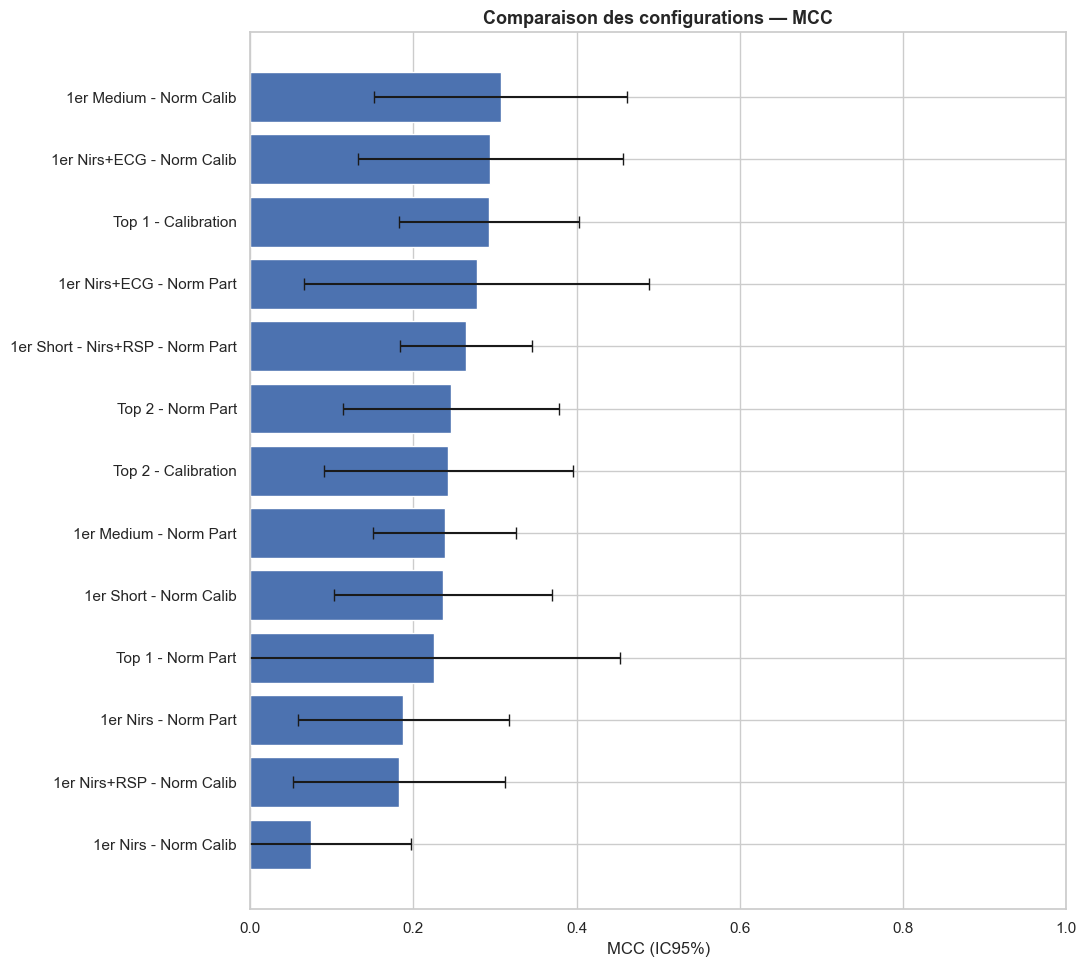

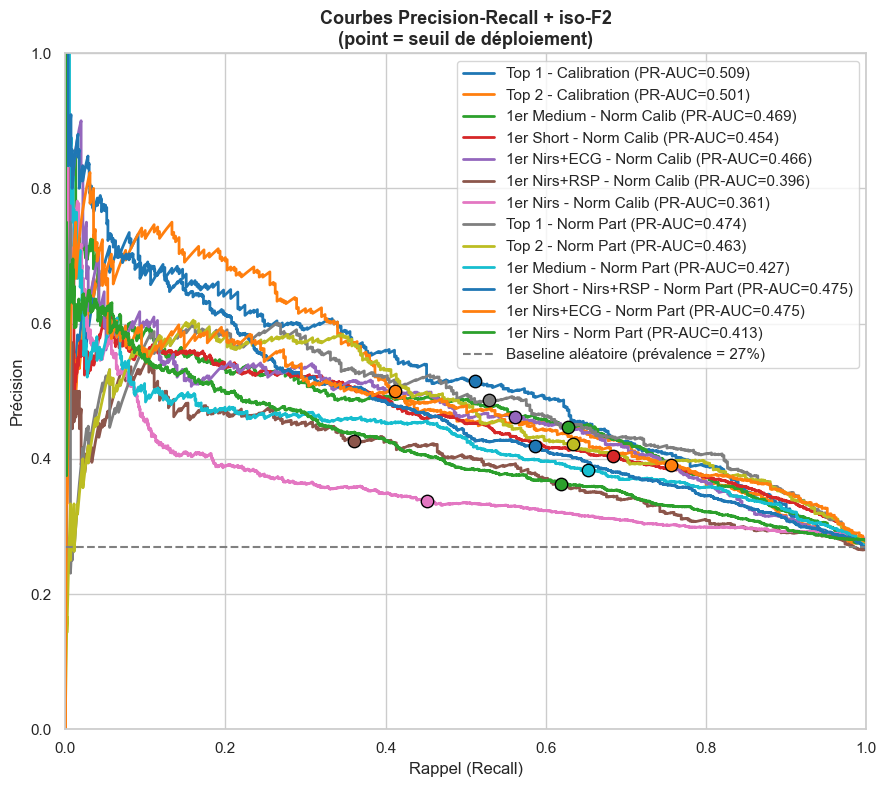

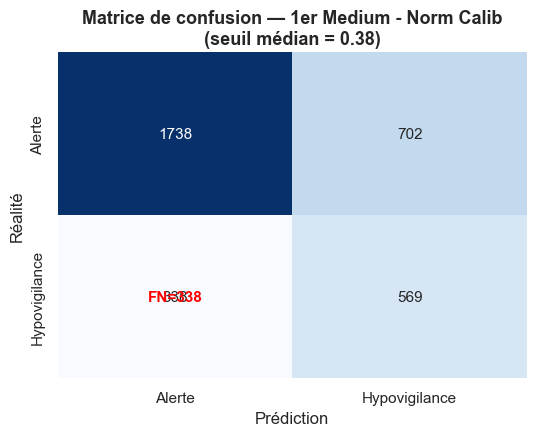

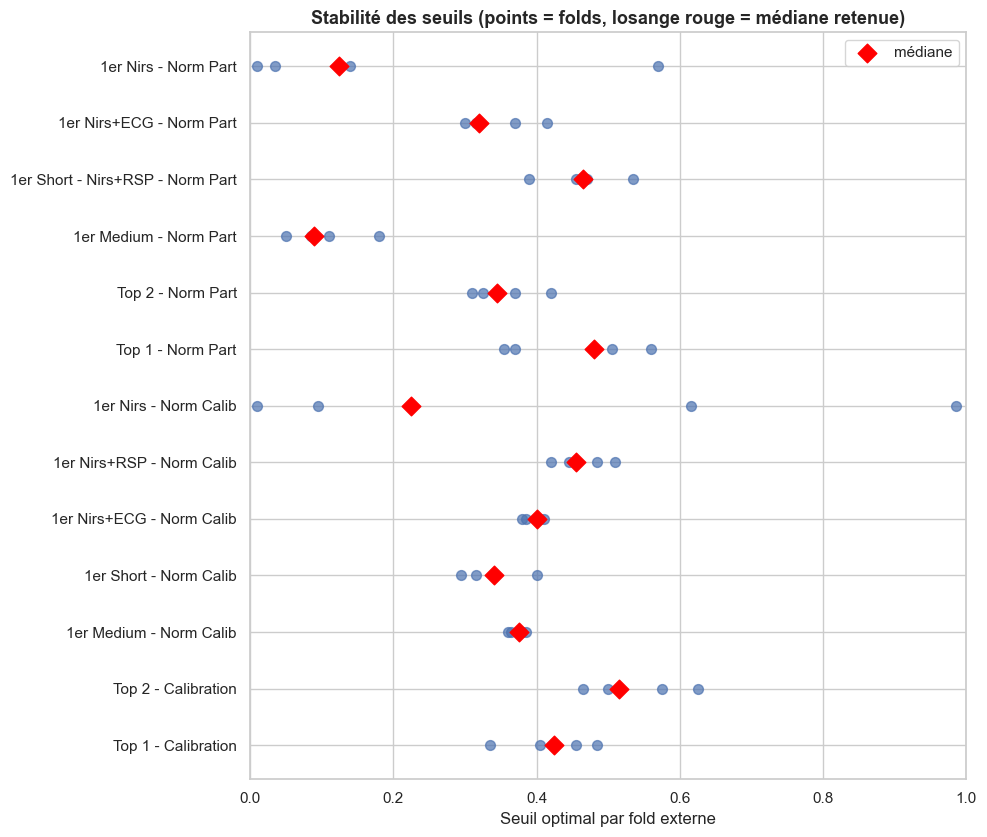

Toutes les figures ont été sauvegardées dans : RESULTS_eval_configs_nested_mcc


In [58]:
# ------------------------------------------------------------
# E.1 Comparaison des configurations : F2 avec IC95% (barres horizontales)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 0.6 * len(df_res) + 2))
order = df_res.sort_values("OPT_mean")
err_low  = order["OPT_mean"] - order["OPT_low"]
err_high = order["OPT_high"] - order["OPT_mean"]
ax.barh(order["Config"], order["OPT_mean"], xerr=[err_low, err_high], capsize=4, color="#4C72B0")
ax.set_xlabel(f"{OPT_LABEL} (IC95%)")
ax.set_title(f"Comparaison des configurations — {OPT_LABEL}", fontweight="bold")
ax.set_xlim(0, 1.0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig1_comparaison_F2.png", dpi=150)
plt.show()


# ------------------------------------------------------------
# E.2 Courbes Precision-Recall + iso-lignes F2 (toutes les configs)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 8))

# Iso-lignes de F2 (courbes de niveau) — repère visuel
recall_grid    = np.linspace(0.01, 1, 200)
precision_grid = np.linspace(0.01, 1, 200)
R, P = np.meshgrid(recall_grid, precision_grid)
BETA_ISO = {"f1": 1, "f2": 2}.get(THRESHOLD_METRIC, None)
if BETA_ISO is not None:
    b2 = BETA_ISO ** 2
    with np.errstate(divide="ignore", invalid="ignore"):
        Fb_grid = (1 + b2) * (P * R) / (b2 * P + R)
    cs = ax.contour(R, P, Fb_grid, levels=[0.2, 0.4, 0.6, 0.8],
                    colors="grey", linestyles="dashed", alpha=0.6)
    ax.clabel(cs, inline=True, fmt=f"F{BETA_ISO}=%.1f", fontsize=8)
# Si MCC/Youden/G-mean choisi : on affiche juste les courbes PR sans iso-lignes Fβ.

colors = sns.color_palette("tab10", len(oof_store))
for i, (name, d) in enumerate(oof_store.items()):
    prec, rec, _ = precision_recall_curve(d["y_true"], d["y_proba"])
    ax.plot(rec, prec, color=colors[i], lw=2,
            label=f"{name} (PR-AUC={d['pr_auc']:.3f})")
    # Point du seuil de déploiement (médian) marqué sur la courbe
    pred_dep = (d["y_proba"] >= d["thr_deploy"]).astype(int)
    r_pt = recall_score(d["y_true"], pred_dep, zero_division=0)
    p_pt = precision_score(d["y_true"], pred_dep, zero_division=0)
    ax.scatter([r_pt], [p_pt], color=colors[i], s=80, zorder=5,
               edgecolor="black", linewidth=1)

ax.set_xlabel("Rappel (Recall)")
ax.set_ylabel("Précision")
ax.set_title("Courbes Precision-Recall + iso-F2\n(point = seuil de déploiement)",
             fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="lower left", fontsize=8)
prevalence = 0.27
ax.axhline(prevalence, ls="--", color="grey", lw=1.5,
           label=f"Baseline aléatoire (prévalence = {prevalence:.0%})")
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig2_courbes_PR_isoF2.png", dpi=150)
plt.show()


# ------------------------------------------------------------
# E.3 Matrice de confusion de la MEILLEURE configuration (au seuil médian)
#     Met en évidence les faux négatifs (épisodes ratés) — enjeu sécurité
# ------------------------------------------------------------
best_name = df_res.iloc[0]["Config"]     # tri déjà par F2 décroissant
d_best = oof_store[best_name]
pred_best = (d_best["y_proba"] >= d_best["thr_deploy"]).astype(int)
cm = confusion_matrix(d_best["y_true"], pred_best, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Alerte", "Hypovigilance"],
            yticklabels=["Alerte", "Hypovigilance"], ax=ax)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
ax.set_title(f"Matrice de confusion — {best_name}\n"
             f"(seuil médian = {d_best['thr_deploy']:.2f})", fontweight="bold")
# Annotation explicite du nombre de faux négatifs (case réalité=1, prédit=0)
fn = cm[1, 0]
ax.text(0.5, 1.5, f"FN={fn}", ha="center", va="center",
        color="red", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig3_matrice_confusion_best.png", dpi=150)
plt.show()


# ------------------------------------------------------------
# E.4 Stabilité des seuils par configuration (les 5 seuils des folds externes)
#     Montre la robustesse : seuils resserrés = modèle stable
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 0.5 * len(thr_store) + 2))
for i, (name, thrs) in enumerate(thr_store.items()):
    ax.scatter(thrs, [i] * len(thrs), color="#4C72B0", s=50, alpha=0.7, zorder=3)
    ax.scatter([np.median(thrs)], [i], color="red", marker="D", s=90,
               zorder=4, label="médiane" if i == 0 else None)
ax.set_yticks(range(len(thr_store)))
ax.set_yticklabels(list(thr_store.keys()))
ax.set_xlabel("Seuil optimal par fold externe")
ax.set_title("Stabilité des seuils (points = folds, losange rouge = médiane retenue)",
             fontweight="bold")
ax.set_xlim(0, 1)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig4_stabilite_seuils.png", dpi=150)
plt.show()

print("Toutes les figures ont été sauvegardées dans :", OUTPUT_DIR_EVAL)


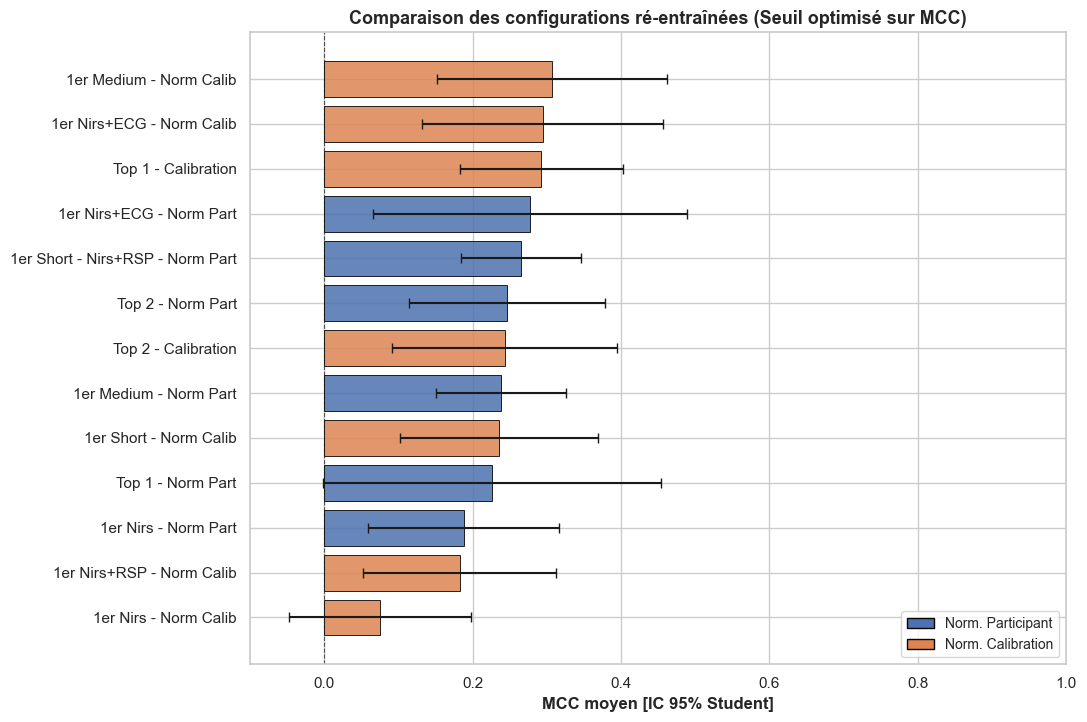

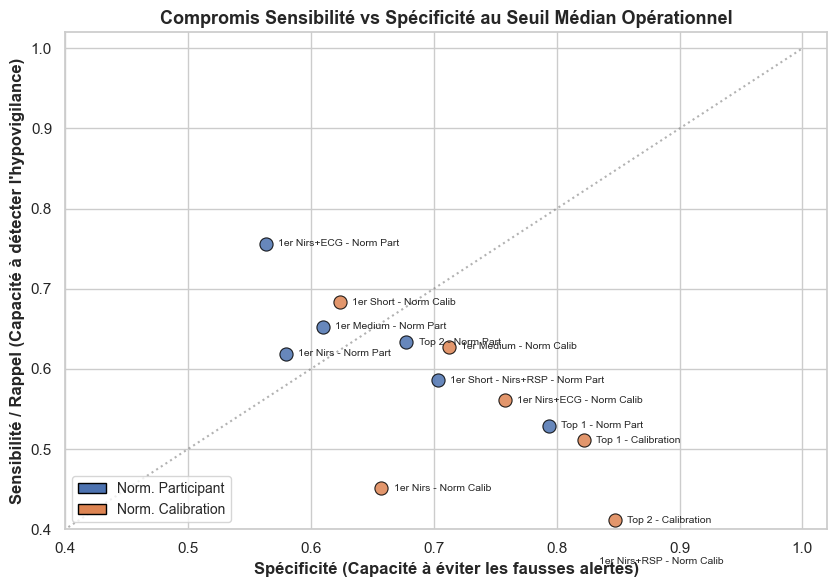

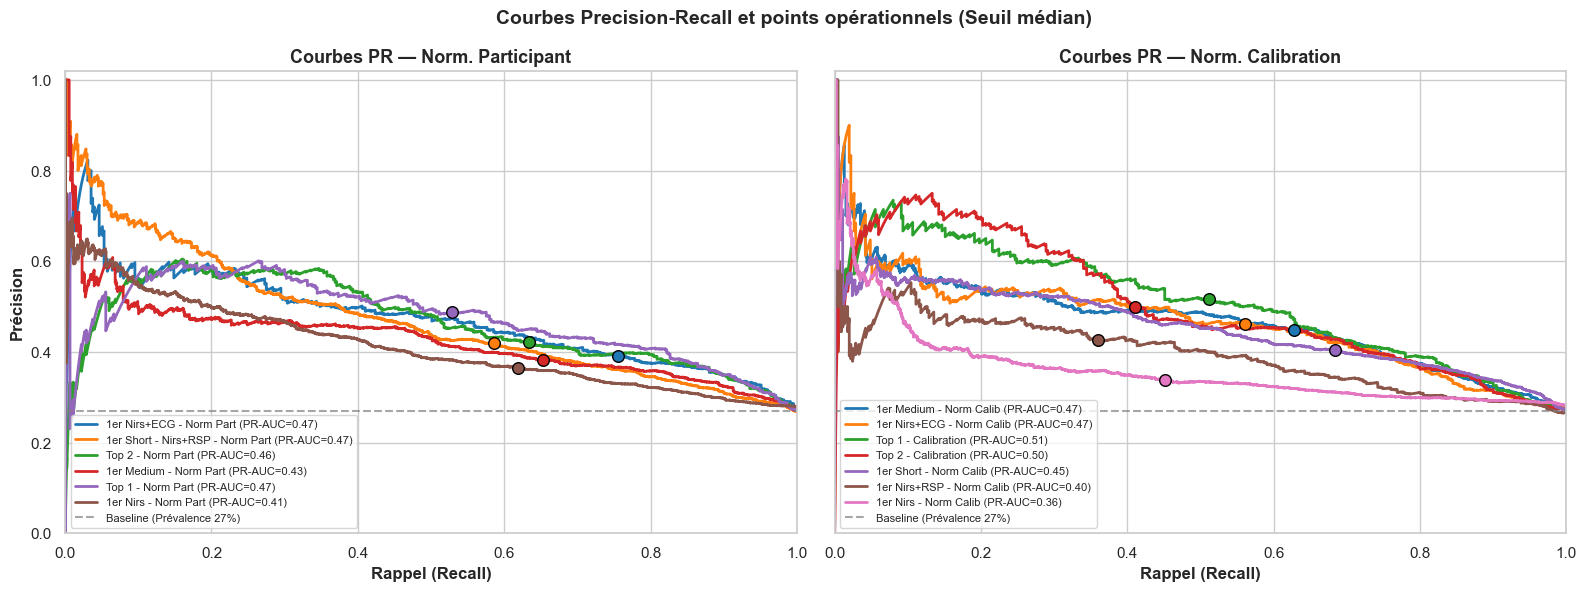

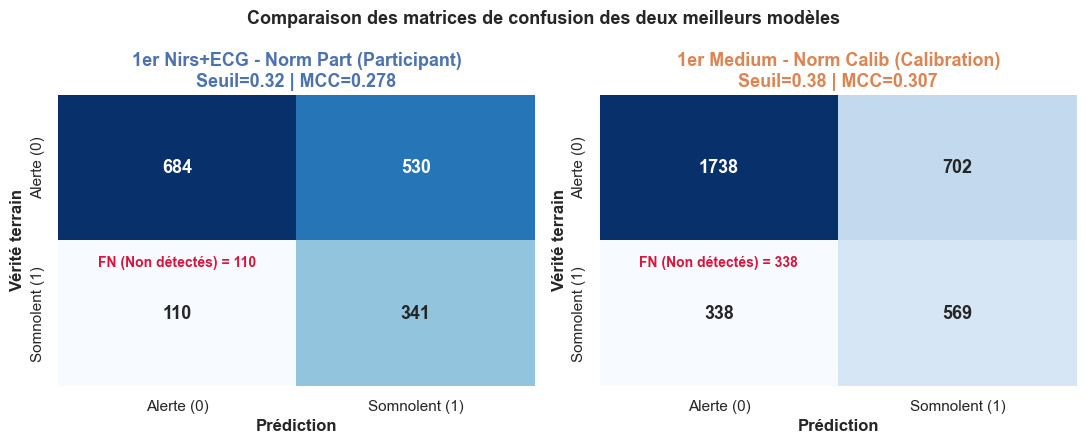

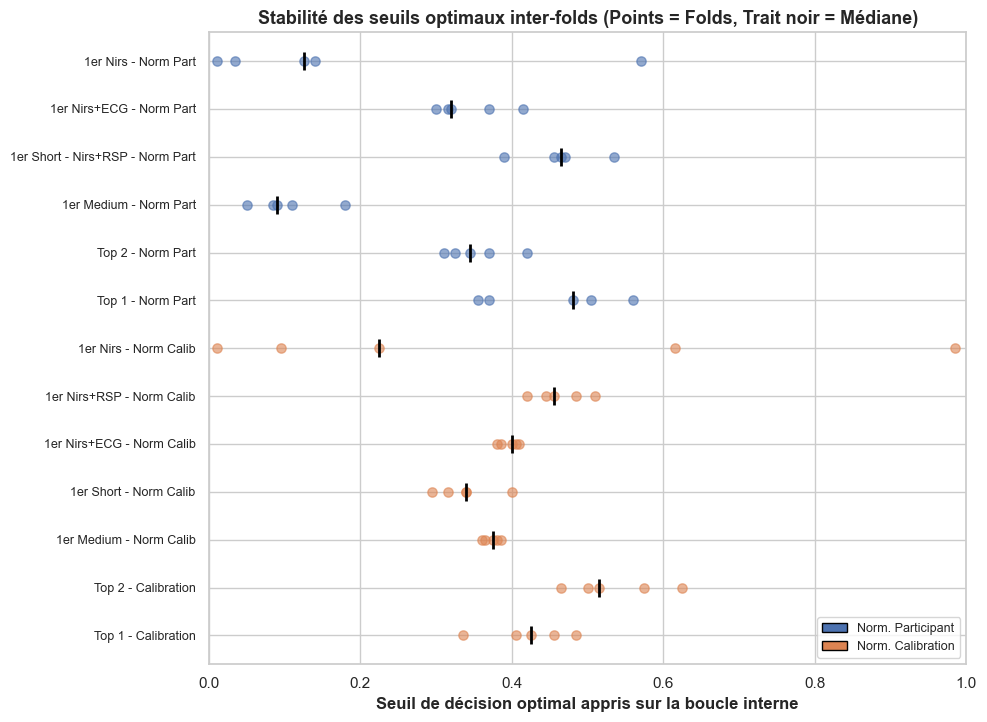


[OK] Toutes les figures ont été sauvegardées dans : RESULTS_eval_configs_nested_mcc


In [62]:
# ============================================================
#  BLOC E — VISUALISATIONS DE L'ÉVALUATION FINALE (OPTIMISATION SEUIL MCC)
#  - Palette cohérente : Bleu = Participant, Orange = Calibration
#  - Résolution DPI définie
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.metrics import precision_recall_curve, confusion_matrix, recall_score, precision_score

# Résolution des figures
DPI = 150

# Palette de couleurs globale
PALETTE_NORM = {"participant": "#4C72B0", "calibration_mean_std": "#DD8452"}
LABEL_NORM = {"participant": "Participant", "calibration_mean_std": "Calibration"}

df_res["norm_clean"] = df_res["Normalisation"].map(LABEL_NORM).fillna(df_res["Normalisation"])
df_res["color"] = df_res["Normalisation"].map(PALETTE_NORM).fillna("#7f7f7f")

legend_elements = [
    Patch(facecolor=PALETTE_NORM["participant"], edgecolor="black", label="Norm. Participant"),
    Patch(facecolor=PALETTE_NORM["calibration_mean_std"], edgecolor="black", label="Norm. Calibration")
]


# ------------------------------------------------------------
# E.1 Comparaison des 13 configurations : MCC (IC95%) coloré par Normalisation
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, max(5, 0.45 * len(df_res) + 1.5)))

order = df_res.sort_values("OPT_mean", ascending=True)
err_low  = order["OPT_mean"] - order["OPT_low"]
err_high = order["OPT_high"] - order["OPT_mean"]

bars = ax.barh(
    order["Config"],
    order["OPT_mean"],
    xerr=[err_low, err_high],
    color=order["color"],
    capsize=3.5,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.85
)

ax.legend(handles=legend_elements, loc="lower right", fontsize=10)
ax.set_xlabel("MCC moyen [IC 95% Student]", fontweight="bold")
ax.set_title("Comparaison des configurations ré-entraînées (Seuil optimisé sur MCC)", fontweight="bold")
ax.set_xlim(-0.1, 1.0)
ax.axvline(0, color="k", linestyle="--", linewidth=0.8, alpha=0.7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig1_comparaison_MCC_par_norm.png", dpi=DPI, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# E.2 Compromis Opérationnel au seuil : Sensibilité vs Spécificité (Pointplot)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 6))

for _, r in df_res.iterrows():
    name = r["Config"]
    d = oof_store[name]
    pred_dep = (d["y_proba"] >= d["thr_deploy"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(d["y_true"], pred_dep, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    c = PALETTE_NORM.get(r["Normalisation"], "#333333")
    ax.scatter(spec, sens, color=c, s=90, edgecolor="black", linewidth=0.8, alpha=0.85)
    ax.text(spec + 0.01, sens, name, fontsize=7.5, verticalalignment="center")

ax.set_xlabel("Spécificité (Capacité à éviter les fausses alertes)", fontweight="bold")
ax.set_ylabel("Sensibilité / Rappel (Capacité à détecter l'hypovigilance)", fontweight="bold")
ax.set_title("Compromis Sensibilité vs Spécificité au Seuil Médian Opérationnel", fontweight="bold")
ax.legend(handles=legend_elements, loc="lower left", fontsize=10)
ax.set_xlim(0.4, 1.02)
ax.set_ylim(0.4, 1.02)
ax.plot([0, 1], [0, 1], linestyle=":", color="grey", alpha=0.6)

plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig2_tradeoff_sensibilite_specificite.png", dpi=DPI, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# E.3 Courbes Precision-Recall séparées en 2 sous-graphiques (Participant vs Calibration)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, (norm_key, norm_title) in zip(axes, [("participant", "Norm. Participant"), 
                                            ("calibration_mean_std", "Norm. Calibration")]):
    sub_configs = df_res[df_res["Normalisation"] == norm_key]["Config"].tolist()
    palette_sub = sns.color_palette("tab10", len(sub_configs))
    
    for i, name in enumerate(sub_configs):
        d = oof_store[name]
        prec, rec, _ = precision_recall_curve(d["y_true"], d["y_proba"])
        ax.plot(rec, prec, color=palette_sub[i], lw=2, label=f"{name} (PR-AUC={d['pr_auc']:.2f})")
        
        # Point du seuil optimal de déploiement
        pred_dep = (d["y_proba"] >= d["thr_deploy"]).astype(int)
        r_pt = recall_score(d["y_true"], pred_dep, zero_division=0)
        p_pt = precision_score(d["y_true"], pred_dep, zero_division=0)
        ax.scatter([r_pt], [p_pt], color=palette_sub[i], s=70, zorder=5, edgecolor="black")

    ax.axhline(0.27, ls="--", color="grey", alpha=0.7, label="Baseline (Prévalence 27%)")
    ax.set_xlabel("Rappel (Recall)", fontweight="bold")
    ax.set_title(f"Courbes PR — {norm_title}", fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower left", fontsize=8)

axes[0].set_ylabel("Précision", fontweight="bold")
fig.suptitle("Courbes Precision-Recall et points opérationnels (Seuil médian)", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig3_courbes_PR_par_normalisation.png", dpi=DPI, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# E.4 Matrices de confusion des 2 MEILLEURS modèles (1 Participant vs 1 Calibration)
# ------------------------------------------------------------
best_part = df_res[df_res["Normalisation"] == "participant"].sort_values("OPT_mean", ascending=False).iloc[0]
best_calib = df_res[df_res["Normalisation"] == "calibration_mean_std"].sort_values("OPT_mean", ascending=False).iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, r, color_title in zip(axes, [best_part, best_calib], [PALETTE_NORM["participant"], PALETTE_NORM["calibration_mean_std"]]):
    name = r["Config"]
    d = oof_store[name]
    pred_best = (d["y_proba"] >= d["thr_deploy"]).astype(int)
    cm = confusion_matrix(d["y_true"], pred_best, labels=[0, 1])
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 13, "fontweight": "bold"},
                xticklabels=["Alerte (0)", "Somnolent (1)"],
                yticklabels=["Alerte (0)", "Somnolent (1)"])
    
    ax.set_xlabel("Prédiction", fontweight="bold")
    ax.set_ylabel("Vérité terrain", fontweight="bold")
    ax.set_title(f"{name} ({LABEL_NORM.get(r['Normalisation'])})\nSeuil={d['thr_deploy']:.2f} | MCC={r['OPT_mean']:.3f}", 
                 fontweight="bold", color=color_title)
    
    fn = cm[1, 0]
    ax.text(0.5, 1.15, f"FN (Non détectés) = {fn}", ha="center", va="center", color="crimson", fontweight="bold", fontsize=10)

fig.suptitle("Comparaison des matrices de confusion des deux meilleurs modèles", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig4_matrices_confusion_best_duo.png", dpi=DPI, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# E.5 Stabilité des seuils optimaux (5 folds externes) par configuration
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(thr_store) + 1.5)))

for i, (name, thrs) in enumerate(thr_store.items()):
    norm = df_res[df_res["Config"] == name]["Normalisation"].values[0]
    c = PALETTE_NORM.get(norm, "#4C72B0")
    
    # Points de chaque fold
    ax.scatter(thrs, [i] * len(thrs), color=c, s=45, alpha=0.6, zorder=3)
    # Médiane
    ax.scatter([np.median(thrs)], [i], color="black", marker="|", s=180, linewidth=2, zorder=4)

ax.set_yticks(range(len(thr_store)))
ax.set_yticklabels(list(thr_store.keys()), fontsize=9)
ax.set_xlabel("Seuil de décision optimal appris sur la boucle interne", fontweight="bold")
ax.set_title("Stabilité des seuils optimaux inter-folds (Points = Folds, Trait noir = Médiane)", fontweight="bold")
ax.set_xlim(0, 1)
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR_EVAL / "fig5_stabilite_seuils_par_norm.png", dpi=DPI, bbox_inches="tight")
plt.show()

print(f"\n[OK] Toutes les figures ont été sauvegardées dans : {OUTPUT_DIR_EVAL}")

Figure sauvegardée : RESULTS_finaux_zscore_calibration\figure_features_counts_corrigee_long_step30_nirs60_bio180_ds_nirs_ecg_rsp.png


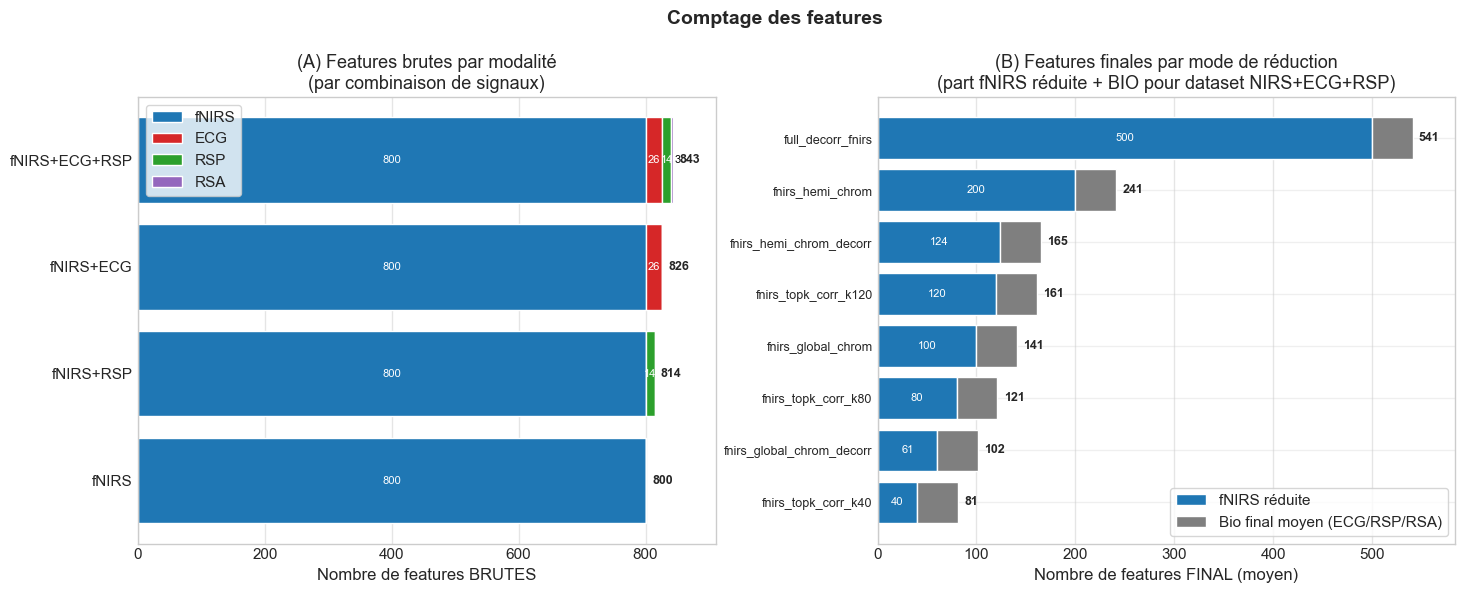


=== Contrôle BIO ===
BIO brut pour ds_nirs_ecg_rsp.csv : ECG=26, RSP=14, RSA=3 -> total BIO brut=43
BIO final moyen par réduction = BIO brut - BIO supprimé NaN/const, calculé depuis dropped_features_by_fold.


,dataset_file,label,fNIRS,ECG,RSP,RSA,Total
0,ds_nirs.csv,fNIRS,800.0,0.0,0.0,0.0,800.0
1,ds_nirs_rsp.csv,fNIRS+RSP,800.0,0.0,14.0,0.0,814.0
2,ds_nirs_ecg.csv,fNIRS+ECG,800.0,26.0,0.0,0.0,826.0
3,ds_nirs_ecg_rsp.csv,fNIRS+ECG+RSP,800.0,26.0,14.0,3.0,843.0


,reduction_mode,fnirs_final,bio_final,total_final,n_folds,n_models_mean
0,fnirs_topk_corr_k40,40.0,41.0,81.0,5,8.0
1,fnirs_global_chrom_decorr,60.6,41.0,101.6,5,8.0
2,fnirs_topk_corr_k80,80.0,41.0,121.0,5,8.0
3,fnirs_global_chrom,100.0,41.0,141.0,5,8.0
4,fnirs_topk_corr_k120,120.0,41.0,161.0,5,8.0
5,fnirs_hemi_chrom_decorr,124.2,41.0,165.2,5,8.0
6,fnirs_hemi_chrom,200.0,41.0,241.0,5,8.0
7,full_decorr_fnirs,499.6,41.0,540.6,5,8.0


In [35]:
# ============================================================
# FIGURE FEATURES depuis l'Excel exporté
# Corrige le comptage BIO final : ECG/HRV + RSP + RSA
# = features brutes BIO - features BIO supprimées NaN/const par fold
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# Paramètres modifiables
# -----------------------------
XLSX_PATH = Path(
    "RESULTS_finaux_zscore_calibration/recap_final_zscore_calibration.xlsx"
)

FOLDER_TO_PLOT = globals().get("FOLDER_TO_PLOT", "long_step30_nirs60_bio180")
DATASET_FILE_B = globals().get("DATASET_FILE_B", "ds_nirs_ecg_rsp.csv")

SAVE_FIG = True
DPI = 180

# -----------------------------
# Lecture Excel
# -----------------------------
if not XLSX_PATH.exists():
    raise FileNotFoundError(f"Excel introuvable : {XLSX_PATH}")

xls = pd.ExcelFile(XLSX_PATH)

required_sheets = ["dataset_reports", "fold_results"]
missing = [s for s in required_sheets if s not in xls.sheet_names]
if missing:
    raise ValueError(f"Feuilles manquantes dans l'Excel : {missing}")

dataset_reports = pd.read_excel(xls, "dataset_reports")
fold_results = pd.read_excel(xls, "fold_results")

if "dropped_features_by_fold" in xls.sheet_names:
    dropped_features = pd.read_excel(xls, "dropped_features_by_fold")
else:
    dropped_features = pd.DataFrame()
    print("[WARNING] Feuille dropped_features_by_fold absente : "
          "le BIO final sera supposé égal au BIO brut.")

# -----------------------------
# Helpers robustes modalités
# -----------------------------
def _lower(x):
    return str(x).strip().lower()

def infer_modality_from_feature_name(feature):
    f = _lower(feature)
    if f.startswith("fnirs"):
        return "fNIRS"
    if f.startswith(("ecg", "hrv")):
        return "ECG"
    if f.startswith("rsp"):
        return "RSP"
    if f.startswith("rsa"):
        return "RSA"
    return "OTHER"

def clean_file_label(dataset_file):
    mapping = {
        "ds_nirs.csv": "fNIRS",
        "ds_nirs_ecg.csv": "fNIRS+ECG",
        "ds_nirs_rsp.csv": "fNIRS+RSP",
        "ds_nirs_ecg_rsp.csv": "fNIRS+ECG+RSP",
    }
    return mapping.get(str(dataset_file), str(dataset_file))

def nice_int(x):
    if pd.isna(x):
        return ""
    return f"{int(round(float(x)))}"

def safe_num(s, default=0):
    try:
        return float(s)
    except Exception:
        return default

# -----------------------------
# Choix du folder existant
# -----------------------------
available_folders = sorted(dataset_reports["dataset_folder"].dropna().astype(str).unique())

if FOLDER_TO_PLOT not in available_folders:
    old = FOLDER_TO_PLOT
    FOLDER_TO_PLOT = available_folders[0]
    print(f"[WARNING] Folder demandé absent ({old}). Folder utilisé : {FOLDER_TO_PLOT}")

rep_folder = dataset_reports[
    dataset_reports["dataset_folder"].astype(str).eq(FOLDER_TO_PLOT)
].copy()

if rep_folder.empty:
    raise ValueError(f"Aucun dataset_report pour folder={FOLDER_TO_PLOT}")

# ============================================================
# PANEL A — features brutes par modalité
# ============================================================
panel_a_files_order = [
    "ds_nirs.csv",
    "ds_nirs_rsp.csv",
    "ds_nirs_ecg.csv",
    "ds_nirs_ecg_rsp.csv",
]  # ordre barh : dernier affiché en haut

rows_a = []

for f in panel_a_files_order:
    r = rep_folder[rep_folder["dataset_file"].astype(str).eq(f)]
    if r.empty:
        continue

    r = r.iloc[0]
    n_fnirs = safe_num(r.get("n_fnirs_features", 0))
    n_ecg   = safe_num(r.get("n_ecg_features", 0))
    n_rsp   = safe_num(r.get("n_rsp_features", 0))
    n_rsa   = safe_num(r.get("n_rsa_features", 0))

    rows_a.append({
        "dataset_file": f,
        "label": clean_file_label(f),
        "fNIRS": n_fnirs,
        "ECG": n_ecg,
        "RSP": n_rsp,
        "RSA": n_rsa,
        "Total": n_fnirs + n_ecg + n_rsp + n_rsa,
    })

dfA = pd.DataFrame(rows_a)

if dfA.empty:
    raise ValueError("Impossible de construire le panel A : aucun fichier dataset trouvé.")

# ============================================================
# PANEL B — features finales par mode de réduction
# BIO corrigé : raw BIO - dropped BIO NaN/const par fold/modèle
# ============================================================
rep_b = rep_folder[rep_folder["dataset_file"].astype(str).eq(DATASET_FILE_B)]

if rep_b.empty:
    raise ValueError(
        f"Aucun dataset_report pour {FOLDER_TO_PLOT}/{DATASET_FILE_B}. "
        f"Fichiers disponibles : {rep_folder['dataset_file'].unique().tolist()}"
    )

rep_b = rep_b.iloc[0]

raw_ecg = safe_num(rep_b.get("n_ecg_features", 0))
raw_rsp = safe_num(rep_b.get("n_rsp_features", 0))
raw_rsa = safe_num(rep_b.get("n_rsa_features", 0))
raw_bio = raw_ecg + raw_rsp + raw_rsa

fr = fold_results.copy()
fr = fr[
    fr["dataset_folder"].astype(str).eq(FOLDER_TO_PLOT)
    & fr["dataset_file"].astype(str).eq(DATASET_FILE_B)
].copy()

if "status" in fr.columns:
    fr = fr[fr["status"].astype(str).eq("ok")].copy()

if fr.empty:
    raise ValueError(f"Aucun fold_result OK pour {FOLDER_TO_PLOT}/{DATASET_FILE_B}")

# Comptage des features BIO supprimées par qualité, par setting/fold/modèle
if not dropped_features.empty:
    dfd = dropped_features.copy()
    dfd = dfd[
        dfd["dataset_folder"].astype(str).eq(FOLDER_TO_PLOT)
        & dfd["dataset_file"].astype(str).eq(DATASET_FILE_B)
    ].copy()

    if not dfd.empty:
        dfd["modality"] = dfd["feature"].apply(infer_modality_from_feature_name)
        dfd = dfd[
            dfd["modality"].isin(["ECG", "RSP", "RSA"])
            & dfd["reason"].astype(str).isin(["too_many_nan", "constant"])
        ].copy()

    if not dfd.empty:
        bio_drop = (
            dfd.groupby(["reduction_mode", "model", "fold"])["feature"]
            .nunique()
            .reset_index(name="n_dropped_bio_quality")
        )
    else:
        bio_drop = pd.DataFrame(
            columns=["reduction_mode", "model", "fold", "n_dropped_bio_quality"]
        )
else:
    bio_drop = pd.DataFrame(
        columns=["reduction_mode", "model", "fold", "n_dropped_bio_quality"]
    )

fr = fr.merge(
    bio_drop,
    on=["reduction_mode", "model", "fold"],
    how="left"
)

fr["n_dropped_bio_quality"] = fr["n_dropped_bio_quality"].fillna(0).astype(float)
fr["bio_final"] = (raw_bio - fr["n_dropped_bio_quality"]).clip(lower=0)

# fNIRS final = total final - BIO final
fr["n_features_final"] = pd.to_numeric(fr["n_features_final"], errors="coerce")
fr["fnirs_final"] = (fr["n_features_final"] - fr["bio_final"]).clip(lower=0)

# Moyenne propre : d'abord fold-level pour éviter de surpondérer les modèles
fold_level = (
    fr.groupby(["reduction_mode", "fold"], as_index=False)
    .agg(
        fnirs_final=("fnirs_final", "mean"),
        bio_final=("bio_final", "mean"),
        n_features_final=("n_features_final", "mean"),
        n_models=("model", "nunique"),
    )
)

dfB = (
    fold_level.groupby("reduction_mode", as_index=False)
    .agg(
        fnirs_final=("fnirs_final", "mean"),
        bio_final=("bio_final", "mean"),
        total_final=("n_features_final", "mean"),
        n_folds=("fold", "nunique"),
        n_models_mean=("n_models", "mean"),
    )
)

# Ordre visuel souhaité, du bas vers le haut
desired_order_b = [
    "fnirs_topk_corr_k40",
    "fnirs_global_chrom_decorr",
    "fnirs_topk_corr_k80",
    "fnirs_global_chrom",
    "fnirs_topk_corr_k120",
    "fnirs_hemi_chrom_decorr",
    "fnirs_hemi_chrom",
    "full_decorr_fnirs",
]

present = dfB["reduction_mode"].tolist()
ordered_present = [x for x in desired_order_b if x in present]
ordered_present += [x for x in present if x not in ordered_present]

dfB["reduction_mode"] = pd.Categorical(
    dfB["reduction_mode"],
    categories=ordered_present,
    ordered=True
)
dfB = dfB.sort_values("reduction_mode").reset_index(drop=True)

# ============================================================
# Plot
# ============================================================
plt.style.use("seaborn-v0_8-whitegrid")

colors = {
    "fNIRS": "#1f77b4",
    "ECG": "#d62728",
    "RSP": "#2ca02c",
    "RSA": "#9467bd",
    "BIO": "#7f7f7f",
}

fig, axes = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw={"wspace": 0.28})

# -----------------------------
# Panel A
# -----------------------------
ax = axes[0]
y = np.arange(len(dfA))
left = np.zeros(len(dfA))

for mod in ["fNIRS", "ECG", "RSP", "RSA"]:
    vals = dfA[mod].values.astype(float)
    ax.barh(
        y,
        vals,
        left=left,
        color=colors[mod],
        edgecolor="white",
        linewidth=1.0,
        label=mod,
    )

    for i, v in enumerate(vals):
        if v >= 8:
            ax.text(
                left[i] + v / 2,
                y[i],
                nice_int(v),
                ha="center",
                va="center",
                color="white",
                fontsize=8,
            )
        elif v > 0:
            ax.text(
                left[i] + v + 2,
                y[i],
                nice_int(v),
                ha="left",
                va="center",
                color="black",
                fontsize=8,
            )

    left += vals

for i, total in enumerate(dfA["Total"].values):
    ax.text(
        total + max(dfA["Total"]) * 0.012,
        y[i],
        nice_int(total),
        ha="left",
        va="center",
        fontweight="bold",
        fontsize=9,
    )

ax.set_yticks(y)
ax.set_yticklabels(dfA["label"], fontsize=11)
ax.set_xlabel("Nombre de features BRUTES", fontsize=12)
ax.set_title(
    "(A) Features brutes par modalité\n(par combinaison de signaux)",
    fontsize=13,
)
ax.set_xlim(0, max(dfA["Total"]) * 1.08)
ax.legend(loc="upper left", frameon=True)
ax.grid(axis="x", alpha=0.5)
ax.grid(axis="y", visible=False)

# -----------------------------
# Panel B
# -----------------------------
ax = axes[1]
y = np.arange(len(dfB))

fnirs_vals = dfB["fnirs_final"].values.astype(float)
bio_vals = dfB["bio_final"].values.astype(float)
total_vals = fnirs_vals + bio_vals

ax.barh(
    y,
    fnirs_vals,
    color=colors["fNIRS"],
    edgecolor="white",
    linewidth=1.0,
    label="fNIRS réduite",
)

ax.barh(
    y,
    bio_vals,
    left=fnirs_vals,
    color=colors["BIO"],
    edgecolor="white",
    linewidth=1.0,
    label="Bio final moyen (ECG/RSP/RSA)",
)

for i, v in enumerate(fnirs_vals):
    if v >= 20:
        ax.text(
            v / 2,
            y[i],
            nice_int(v),
            ha="center",
            va="center",
            color="white",
            fontsize=8,
        )
    elif v > 0:
        ax.text(
            v + 2,
            y[i],
            nice_int(v),
            ha="left",
            va="center",
            color="white",
            fontsize=8,
        )

for i, total in enumerate(total_vals):
    ax.text(
        total + max(total_vals) * 0.012,
        y[i],
        nice_int(total),
        ha="left",
        va="center",
        fontweight="bold",
        fontsize=9,
    )

ax.set_yticks(y)
ax.set_yticklabels(dfB["reduction_mode"].astype(str), fontsize=9)
ax.set_xlabel("Nombre de features FINAL (moyen)", fontsize=12)
ax.set_title(
    "(B) Features finales par mode de réduction\n(part fNIRS réduite + BIO pour dataset NIRS+ECG+RSP)",
    fontsize=13,
)
ax.set_xlim(0, max(total_vals) * 1.08)
ax.legend(loc="lower right", frameon=True)
ax.grid(axis="x", alpha=0.5)
ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    f"Comptage des features",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

plt.tight_layout()

if SAVE_FIG:
    safe_folder = re.sub(r"[^A-Za-z0-9_.-]+", "_", FOLDER_TO_PLOT)
    safe_file = re.sub(r"[^A-Za-z0-9_.-]+", "_", DATASET_FILE_B.replace(".csv", ""))
    out_png = XLSX_PATH.parent / f"figure_features_counts_corrigee_{safe_folder}_{safe_file}.png"
    plt.savefig(out_png, dpi=DPI, bbox_inches="tight")
    print(f"Figure sauvegardée : {out_png}")

plt.show()

# -----------------------------
# Contrôle rapide des valeurs
# -----------------------------
print("\n=== Contrôle BIO ===")
print(f"BIO brut pour {DATASET_FILE_B} : ECG={int(raw_ecg)}, RSP={int(raw_rsp)}, RSA={int(raw_rsa)} -> total BIO brut={int(raw_bio)}")
print("BIO final moyen par réduction = BIO brut - BIO supprimé NaN/const, calculé depuis dropped_features_by_fold.")

display(dfA)
display(dfB)
